# 17. Análisis diario de horizontes 1–15 y estacionalidad semanal

**Pregunta:** ¿la estacionalidad semanal ayuda a explicar la recuperación relativa del SARIMAX alrededor de los horizontes 7 y 14?

Se comparan cuatro modelos probabilísticos (SARIMAX estacional, LSTM cuantílica, TFT + covariables y GRU Bayesiana), dos referencias puntuales (persistencia y persistencia semanal) y un SARIMAX sin estacionalidad como control. Todos los modelos se evalúan en 15 horizontes, con las mismas fechas objetivo **dentro de cada horizonte**.

**Importante sobre interpretación:** los pronósticos SARIMAX, LSTM y TFT usan *walk-forward por bloques de longitud h*, mientras que la GRU produce predicciones directas desde orígenes diarios. Se conserva la implementación previa para continuidad experimental, pero **no son protocolos de origen idéntico**. La comparación es exploratoria; para una conclusión causal/definitiva debe realizarse un experimento adicional de orígenes idénticos para todos. Las covariables futuras reales del SARIMAX y TFT se usan en modo *oracle*; esto no representa un pronóstico operativo sin escenarios o predicciones exógenas disponibles en el origen.

La configuración de GRU se mantiene predefinida (60 rezagos, 32 neuronas, dropout 0.3, lr 0.0005, 6 épocas), pero el cambio a 15 salidas implica un nuevo ajuste del modelo. **No se seleccionan hiperparámetros usando el test.**


In [1]:
# Si es la primera vez que ejecutas este notebook, instala UCT en el entorno tesis-bolsa:
# %pip install uncertainty-toolbox

from pathlib import Path
import os, random, warnings, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

SEED = 333
random.seed(SEED)
np.random.seed(SEED)

def encontrar_raiz_repo():
    actual = Path.cwd().resolve()
    for p in [actual, *actual.parents]:
        if (p / ".git").exists() or ((p / "data" / "processed").exists() and (p / "notebooks").exists()):
            return p
    raise FileNotFoundError("No se encontró la raíz del proyecto tesis-bolsa.")

ROOT = encontrar_raiz_repo()
DATA = ROOT / "data" / "processed"
MODELS = ROOT / "models"
REPORTS = ROOT / "reports" / "analisis_horizontes_1_a_15"
REPORTS.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)

TEST_START = pd.Timestamp("2025-08-01")
TEST_END   = pd.Timestamp("2026-07-31")
HORIZONTES = list(range(1, 16))
COVARIABLES = ["gen_termica", "ONI", "aportes_energia_gwh"]

print("Raíz:", ROOT)
print("Reportes:", REPORTS)

Raíz: /Users/maguverm/Documents/tesis-bolsa
Reportes: /Users/maguverm/Documents/tesis-bolsa/reports/analisis_horizontes_1_a_15


In [2]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else ("cuda" if torch.cuda.is_available() else "cpu")
)

# TFT de GluonTS se mantiene en CPU por compatibilidad con la implementación original.
# Permitimos que PyTorch use los núcleos CPU disponibles para ese entrenamiento.
N_CPU = os.cpu_count() or 1
torch.set_num_threads(N_CPU)

if torch.backends.mps.is_available():
    torch.mps.manual_seed(SEED)
torch.manual_seed(SEED)

print("Dispositivo redes PyTorch:", device)
print("Hilos CPU disponibles para TFT:", N_CPU)

Dispositivo redes PyTorch: mps
Hilos CPU disponibles para TFT: 18


In [3]:
df = pd.read_parquet(DATA / "dataset_consolidado.parquet").copy()
df.index = pd.to_datetime(df.index)
df = df.sort_index()

faltantes = [c for c in ["precio_bolsa", *COVARIABLES] if c not in df.columns]
if faltantes:
    raise KeyError(f"Faltan columnas necesarias: {faltantes}")

train_df = df[df.index < TEST_START].copy()
test_df  = df[(df.index >= TEST_START) & (df.index <= TEST_END)].copy()

print("Train:", train_df.index.min().date(), "→", train_df.index.max().date(), len(train_df))
print("Test: ", test_df.index.min().date(), "→", test_df.index.max().date(), len(test_df))

Train: 2013-01-01 → 2025-07-31 4595
Test:  2025-08-01 → 2026-07-31 365


## 1. Funciones comunes

Cada modelo se normaliza al mismo formato:

`fecha | real | pred | p10 | p50 | p90 | std`

`std` es la desviación predictiva nativa cuando existe; para modelos cuantílicos se usa una desviación gaussiana equivalente derivada de P10–P90 para poder aplicar las métricas de `uncertainty-toolbox` que exigen media y desviación estándar.

In [4]:
from sklearn.metrics import r2_score, median_absolute_error, max_error

Z90 = 1.2815515655446004  # cuantil N(0,1) correspondiente a 0.90

def std_equivalente_p10_p90(p10, p90, piso=1e-6):
    p10 = np.asarray(p10, dtype=float)
    p90 = np.asarray(p90, dtype=float)
    return np.maximum((p90 - p10) / (2 * Z90), piso)

def asegurar_intervalos(p10, p50, p90):
    arr = np.vstack([p10, p50, p90]).T
    arr = np.sort(arr, axis=1)
    return arr[:,0], arr[:,1], arr[:,2]

def metricas_puntuales(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {
        "MAE": np.mean(np.abs(y-p)),
        "RMSE": np.sqrt(np.mean((y-p)**2)),
        "MAPE (%)": np.mean(np.abs((y-p)/np.maximum(np.abs(y),1e-8)))*100,
        "sMAPE (%)": np.mean(2*np.abs(y-p)/(np.abs(y)+np.abs(p)+1e-8))*100,
        "R²": r2_score(y,p),
        "MedAE": median_absolute_error(y,p),
        "MaxError": max_error(y,p),
        "Sesgo": np.mean(p-y),
    }

def metricas_intervalo(y, p10, p90):
    y = np.asarray(y,float); p10=np.asarray(p10,float); p90=np.asarray(p90,float)
    dentro = (y >= p10) & (y <= p90)
    ancho = p90-p10
    # Interval score central 80%, alpha=0.20
    alpha = 0.20
    score = ancho + (2/alpha)*(p10-y)*(y<p10) + (2/alpha)*(y-p90)*(y>p90)
    return {
        "Cobertura 80% (%)": dentro.mean()*100,
        "Ancho P10-P90": ancho.mean(),
        "Interval score 80%": score.mean(),
    }

def normalizar_salida(modelo, h, fechas, real, pred, p10, p50, p90, std=None, origen=""):
    p10,p50,p90 = asegurar_intervalos(p10,p50,p90)
    if std is None:
        std = std_equivalente_p10_p90(p10,p90)
    z = pd.DataFrame({
        "Modelo": modelo, "Horizonte": h, "real": np.asarray(real,float),
        "pred": np.asarray(pred,float), "p10": p10, "p50": p50, "p90": p90,
        "std": np.maximum(np.asarray(std,float),1e-6),
        "Origen_incertidumbre": origen
    }, index=pd.to_datetime(fechas))
    z.index.name = "fecha"
    return z.sort_index()

## 2. SARIMAX estacional y control sin estacionalidad

El control SARIMAX(2,0,2) sin componente semanal conserva el resto de la especificación y las covariables. Se calculan predicciones y bandas para ambos. Se advierte si la optimización no converge. **Las covariables de test son observadas a futuro (oracle).**

In [5]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from scipy.stats import norm

modelo_sarimax = SARIMAX(
    train_df["precio_bolsa"],
    exog=train_df[COVARIABLES],
    order=(2,0,2),
    seasonal_order=(1,0,1,7),
    enforce_stationarity=False,
    enforce_invertibility=False
)
resultado_sarimax = modelo_sarimax.fit(disp=False)
print("SARIMAX ajustado. AIC:", round(resultado_sarimax.aic,2))

def wf_sarimax_prob(resultado_fit, test, pasos):
    filas=[]
    actual=resultado_fit
    for i in range(0,len(test),pasos):
        bloque=min(pasos,len(test)-i)
        exog=test[COVARIABLES].iloc[i:i+bloque]
        fc=actual.get_forecast(steps=bloque, exog=exog)
        pred=np.asarray(fc.predicted_mean)
        se=np.asarray(fc.se_mean)
        p10=pred + norm.ppf(.10)*se
        p90=pred + norm.ppf(.90)*se
        fechas=test.index[i:i+bloque]
        for j,f in enumerate(fechas):
            filas.append((f,test.loc[f,"precio_bolsa"],pred[j],p10[j],pred[j],p90[j],se[j]))
        actual=actual.append(
            test["precio_bolsa"].iloc[i:i+bloque],
            exog=exog, refit=False
        )
    x=pd.DataFrame(filas,columns=["fecha","real","pred","p10","p50","p90","std"]).set_index("fecha")
    return x

resultados = {}
for h in HORIZONTES:
    z=wf_sarimax_prob(resultado_sarimax,test_df,h)
    resultados[("SARIMAX",h)] = normalizar_salida(
        "SARIMAX",h,z.index,z.real,z.pred,z.p10,z.p50,z.p90,z["std"],
        "Distribución predictiva SARIMAX (state-space)"
    )
    print("SARIMAX h=",h,"listo")

/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


SARIMAX ajustado. AIC: 52392.66
SARIMAX h= 1 listo
SARIMAX h= 2 listo
SARIMAX h= 3 listo
SARIMAX h= 4 listo
SARIMAX h= 5 listo
SARIMAX h= 6 listo
SARIMAX h= 7 listo
SARIMAX h= 8 listo
SARIMAX h= 9 listo
SARIMAX h= 10 listo
SARIMAX h= 11 listo
SARIMAX h= 12 listo
SARIMAX h= 13 listo
SARIMAX h= 14 listo
SARIMAX h= 15 listo


## 3. LSTM cuantílica — P10/P50/P90

El LSTM original ya contenía una segunda cabeza cuantílica entrenada con **pinball loss**. Aquí se entrena esa versión y se evalúa en walk-forward para h=1 y h=7. La mediana P50 retroalimenta los pasos internos de cada bloque.

**Nota:** las métricas puntuales de esta sección corresponden a la **LSTM cuantílica (P50)** y no tienen por qué coincidir exactamente con las de la LSTM MSE original de `tabla_metricas.parquet`.

In [6]:
from sklearn.preprocessing import MinMaxScaler

train = train_df["precio_bolsa"]
test = test_df["precio_bolsa"]
VENTANA=30

scaler_lstm=MinMaxScaler()
train_scaled=scaler_lstm.fit_transform(train.values.reshape(-1,1))
test_scaled=scaler_lstm.transform(test.values.reshape(-1,1))

def crear_ventanas(data, ventana=VENTANA):
    X,y=[],[]
    for i in range(len(data)-ventana):
        X.append(data[i:i+ventana]); y.append(data[i+ventana])
    return np.array(X),np.array(y)

X_train,y_train=crear_ventanas(train_scaled)
loader=DataLoader(
    TensorDataset(torch.FloatTensor(X_train),torch.FloatTensor(y_train)),
    batch_size=32,shuffle=True
)

class ModeloLSTMQuantile(nn.Module):
    def __init__(self,input_size=1,hidden_size=64,num_layers=2,n_quantiles=3):
        super().__init__()
        self.lstm=nn.LSTM(input_size,hidden_size,num_layers,batch_first=True,dropout=.2)
        self.fc=nn.Linear(hidden_size,n_quantiles)
    def forward(self,x):
        out,_=self.lstm(x)
        return self.fc(out[:,-1,:])

QUANTILES=[.1,.5,.9]
def pinball_loss(pred,true):
    losses=[]
    true=true.squeeze()
    for i,q in enumerate(QUANTILES):
        e=true-pred[:,i]
        losses.append(torch.maximum((q-1)*e,q*e))
    return torch.mean(torch.stack(losses,dim=1).sum(dim=1))

torch.manual_seed(SEED)
modelo_lstm_q=ModeloLSTMQuantile().to(device)
opt=torch.optim.Adam(modelo_lstm_q.parameters(),lr=.001)

EPOCHS_LSTM_Q=50
for epoch in range(EPOCHS_LSTM_Q):
    modelo_lstm_q.train(); acc=0
    for xb,yb in loader:
        xb,yb=xb.to(device),yb.to(device)
        opt.zero_grad()
        loss=pinball_loss(modelo_lstm_q(xb),yb)
        loss.backward(); opt.step(); acc+=loss.item()
    if (epoch+1)%10==0:
        print(f"LSTM-Q epoch {epoch+1}/{EPOCHS_LSTM_Q} loss={acc/len(loader):.6f}")

LSTM-Q epoch 10/50 loss=0.013261
LSTM-Q epoch 20/50 loss=0.012622
LSTM-Q epoch 30/50 loss=0.012379
LSTM-Q epoch 40/50 loss=0.012055
LSTM-Q epoch 50/50 loss=0.011945


In [7]:
def wf_lstm_quantile(model, train_scaled, test, test_scaled, pasos):
    serie=list(train_scaled.flatten())
    filas=[]
    model.eval()
    for i in range(0,len(test),pasos):
        b=min(pasos,len(test)-i)
        serie_med=list(serie[-VENTANA:])
        for j in range(b):
            seq=np.asarray(serie_med[-VENTANA:],dtype=np.float32).reshape(1,VENTANA,1)
            with torch.no_grad():
                qs=model(torch.FloatTensor(seq).to(device)).cpu().numpy().flatten()
            q10,q50,q90=np.sort(qs)
            vals=scaler_lstm.inverse_transform(np.array([[q10],[q50],[q90]])).flatten()
            fecha=test.index[i+j]
            filas.append((fecha,test.loc[fecha],vals[1],vals[0],vals[1],vals[2]))
            serie_med.append(q50)
        # walk-forward: tras el bloque se revelan los datos reales
        serie.extend(test_scaled[i:i+b].flatten().tolist())
    return pd.DataFrame(filas,columns=["fecha","real","pred","p10","p50","p90"]).set_index("fecha")

for h in HORIZONTES:
    z=wf_lstm_quantile(modelo_lstm_q,train_scaled,test,test_scaled,h)
    resultados[("LSTM cuantílica",h)] = normalizar_salida(
        "LSTM cuantílica",h,z.index,z.real,z.pred,z.p10,z.p50,z.p90,
        origen="Regresión cuantílica P10/P50/P90 (pinball loss)"
    )
    print("LSTM cuantílica h=",h,"lista")

LSTM cuantílica h= 1 lista
LSTM cuantílica h= 2 lista
LSTM cuantílica h= 3 lista
LSTM cuantílica h= 4 lista
LSTM cuantílica h= 5 lista
LSTM cuantílica h= 6 lista
LSTM cuantílica h= 7 lista
LSTM cuantílica h= 8 lista
LSTM cuantílica h= 9 lista
LSTM cuantílica h= 10 lista
LSTM cuantílica h= 11 lista
LSTM cuantílica h= 12 lista
LSTM cuantílica h= 13 lista
LSTM cuantílica h= 14 lista
LSTM cuantílica h= 15 lista


## 4. TFT + covariables — cuantiles nativos de GluonTS

Se conserva la formulación del notebook `08_GluonTS.ipynb`: covariables normalizadas con scaler ajustado solo sobre train y un TFT distinto para cada `prediction_length`.

El TFT original se ejecutaba en **CPU**; se mantiene así por compatibilidad. El resto de redes PyTorch aprovecha MPS cuando está disponible.

In [8]:
from sklearn.preprocessing import StandardScaler
from gluonts.dataset.common import ListDataset
from gluonts.torch.model.tft import TemporalFusionTransformerEstimator

FREQ="D"
train_data=train_df["precio_bolsa"]
test_data=test_df["precio_bolsa"]

scaler_cov=StandardScaler()
scaler_cov.fit(train_df[COVARIABLES])
df_scaled=df.copy()
df_scaled[COVARIABLES]=scaler_cov.transform(df[COVARIABLES])
train_cov_scaled=df_scaled[df_scaled.index<TEST_START]

train_ds_cov=ListDataset([{
    "target":train_cov_scaled["precio_bolsa"].values,
    "start":train_cov_scaled.index[0],
    "feat_dynamic_real":train_cov_scaled[COVARIABLES].values.T
}],freq=FREQ)

def entrenar_tft(h):
    est=TemporalFusionTransformerEstimator(
        freq=FREQ,prediction_length=h,context_length=730,
        trainer_kwargs={"max_epochs":50,"accelerator":"cpu","enable_progress_bar":False}
    )
    return est.train(train_ds_cov)

def wf_tft_prob(predictor,h):
    serie=train_cov_scaled.copy()
    filas=[]
    for i in range(0,len(test_data),h):
        b=min(h,len(test_data)-i)
        fin=test_data.index[i+b-1]
        cov_slice=df_scaled.loc[serie.index[0]:fin,COVARIABLES]
        ds=ListDataset([{
            "target":serie["precio_bolsa"].values,
            "start":serie.index[0],
            "feat_dynamic_real":cov_slice.values.T
        }],freq=FREQ)
        fc=list(predictor.predict(ds))[0]
        mean=np.asarray(fc.mean)[:b]
        q10=np.asarray(fc.quantile(.1))[:b]
        q50=np.asarray(fc.quantile(.5))[:b]
        q90=np.asarray(fc.quantile(.9))[:b]
        fechas=test_data.index[i:i+b]
        for j,f in enumerate(fechas):
            filas.append((f,test_data.loc[f],mean[j],q10[j],q50[j],q90[j]))
        nuevo=df_scaled.loc[fechas,["precio_bolsa",*COVARIABLES]]
        serie=pd.concat([serie,nuevo])
    return pd.DataFrame(filas,columns=["fecha","real","pred","p10","p50","p90"]).set_index("fecha")

predictores_tft={}
for h in HORIZONTES:
    print(f"\nEntrenando TFT + covariables h={h}...")
    predictores_tft[h]=entrenar_tft(h)
    z=wf_tft_prob(predictores_tft[h],h)
    resultados[("TFT + covariables",h)] = normalizar_salida(
        "TFT + covariables",h,z.index,z.real,z.pred,z.p10,z.p50,z.p90,
        origen="Cuantiles probabilísticos nativos de GluonTS"
    )
    print("TFT + covariables h=",h,"listo")

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

  | Name  | Type                           | Params | Mode  | FLOPs  | In sizes                                                                                 | Out sizes                    
-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
0 | model | TemporalFusionTransformerModel | 109 K  | train | 59.9 M | [[1, 730], [1, 730], [1, 1], [1, 1], [1, 731, 3], [1, 731, 0], [1, 730, 0], [1, 730, 0]] | [[[1, 1, 9]], [1, 1], [1, 1]]
-----------------------------------------------------------------------------------------------------------


Entrenando TFT + covariables h=1...


Epoch 0, global step 50: 'train_loss' reached 115.54299 (best 115.54299), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_111/checkpoints/epoch=0-step=50.ckpt' as top 1
Epoch 1, global step 100: 'train_loss' reached 46.21592 (best 46.21592), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_111/checkpoints/epoch=1-step=100.ckpt' as top 1
Epoch 2, global step 150: 'train_loss' reached 39.24791 (best 39.24791), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_111/checkpoints/epoch=2-step=150.ckpt' as top 1
Epoch 3, global step 200: 'train_loss' reached 29.51144 (best 29.51144), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_111/checkpoints/epoch=3-step=200.ckpt' as top 1
Epoch 4, global step 250: 'train_loss' reached 28.72343 (best 28.72343), saving model to '/Users/mag

TFT + covariables h= 1 listo

Entrenando TFT + covariables h=2...


Epoch 0, global step 50: 'train_loss' reached 105.18001 (best 105.18001), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_112/checkpoints/epoch=0-step=50.ckpt' as top 1
Epoch 1, global step 100: 'train_loss' reached 51.47117 (best 51.47117), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_112/checkpoints/epoch=1-step=100.ckpt' as top 1
Epoch 2, global step 150: 'train_loss' reached 43.18515 (best 43.18515), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_112/checkpoints/epoch=2-step=150.ckpt' as top 1
Epoch 3, global step 200: 'train_loss' reached 36.73206 (best 36.73206), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_112/checkpoints/epoch=3-step=200.ckpt' as top 1
Epoch 4, global step 250: 'train_loss' reached 34.17401 (best 34.17401), saving model to '/Users/mag

...

TFT + covariables h= 13 listo

Entrenando TFT + covariables h=14...


Epoch 0, global step 50: 'train_loss' reached 131.66422 (best 131.66422), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_124/checkpoints/epoch=0-step=50.ckpt' as top 1
Epoch 1, global step 100: 'train_loss' reached 110.96907 (best 110.96907), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_124/checkpoints/epoch=1-step=100.ckpt' as top 1
Epoch 2, global step 150: 'train_loss' reached 69.85264 (best 69.85264), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_124/checkpoints/epoch=2-step=150.ckpt' as top 1
Epoch 3, global step 200: 'train_loss' reached 63.56353 (best 63.56353), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_124/checkpoints/epoch=3-step=200.ckpt' as top 1
Epoch 4, global step 250: 'train_loss' reached 59.18669 (best 59.18669), saving model to '/Users/m

TFT + covariables h= 14 listo

Entrenando TFT + covariables h=15...


Epoch 0, global step 50: 'train_loss' reached 120.76702 (best 120.76702), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_125/checkpoints/epoch=0-step=50.ckpt' as top 1
Epoch 1, global step 100: 'train_loss' reached 76.24468 (best 76.24468), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_125/checkpoints/epoch=1-step=100.ckpt' as top 1
Epoch 2, global step 150: 'train_loss' reached 68.23145 (best 68.23145), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_125/checkpoints/epoch=2-step=150.ckpt' as top 1
Epoch 3, global step 200: 'train_loss' reached 60.87609 (best 60.87609), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_125/checkpoints/epoch=3-step=200.ckpt' as top 1
Epoch 4, global step 250: 'train_loss' reached 58.84689 (best 58.84689), saving model to '/Users/mag

TFT + covariables h= 15 listo


## 5. GRU Bayesiana — reentrenamiento y Monte Carlo

Se reproducen features, arquitectura y objetivo log-diferencia del notebook 14. Configuración elegida anteriormente en validación: lookback 60, 32 neuronas, dropout 0.3, lr 0.0005, 6 épocas. Se generan cinco salidas directas y 100 muestras Monte Carlo. **No se selecciona nada usando el test.**

In [9]:
from bayesian_torch.models.dnn_to_bnn import dnn_to_bnn, get_kl_loss
import random
from sklearn.preprocessing import StandardScaler

# Configuración escogida en validación en notebook 14. NO se usa test para escogerla.
GRU_LOOKBACK=60
GRU_NEURONAS=32
GRU_LR=5e-4
GRU_DROPOUT=.3
GRU_EPOCHS=6
GRU_N_MC=100

def ejecutar_gru_bayesiana():
    horizontes_gru=HORIZONTES
    random.seed(42); np.random.seed(42); torch.manual_seed(42)
    datos=pd.read_parquet(DATA/'dataset_consolidado.parquet').copy()
    datos.index=pd.to_datetime(datos.index)
    datos=datos.sort_index()
    datos=datos[~datos.index.duplicated(keep='last')].select_dtypes(include=[np.number])
    TARGET='precio_bolsa'
    df=datos
    # Features de calendario y régimen. Todas usan solo información disponible hasta t.
    p=df[TARGET].astype(float)
    df["dow_sin"]=np.sin(2*np.pi*df.index.dayofweek/7)
    df["dow_cos"]=np.cos(2*np.pi*df.index.dayofweek/7)
    df["month_sin"]=np.sin(2*np.pi*(df.index.month-1)/12)
    df["month_cos"]=np.cos(2*np.pi*(df.index.month-1)/12)
    df["fin_semana"]=(df.index.dayofweek>=5).astype(float)
    
    df["precio_ma7"]=p.rolling(7).mean()
    df["precio_ma30"]=p.rolling(30).mean()
    df["precio_std7"]=p.rolling(7).std()
    df["precio_std30"]=p.rolling(30).std()
    df["precio_min30"]=p.rolling(30).min()
    df["precio_max30"]=p.rolling(30).max()
    df["precio_rel_ma7"]=p/df["precio_ma7"]
    df["precio_rel_ma30"]=p/df["precio_ma30"]
    df["precio_z30"]=(p-df["precio_ma30"])/df["precio_std30"].replace(0,np.nan)
    df["precio_cambio1"]=p.pct_change(1)
    df["precio_cambio7"]=p.pct_change(7)
    
    aliases={
     "aportes":["aportes_energia_gwh","aportes_energia","aportes"],
     "gen_termica":["gen_termica","generacion_termica"],
     "demanda":["demanda","demanda_energia"],
     "vol_util":["vol_util","volumen_util","energia_embalsada"]
    }
    for _,opts in aliases.items():
        col=next((x for x in opts if x in df.columns),None)
        if col:
            df[f"{col}_ma7"]=df[col].rolling(7).mean()
            df[f"{col}_ma30"]=df[col].rolling(30).mean()
            df[f"{col}_cambio7"]=df[col].pct_change(7)
    
    df=df.replace([np.inf,-np.inf],np.nan).dropna().copy()
    FEATURES=list(df.columns)
    print("Features:",len(FEATURES))
    print(FEATURES)

    FEATURES=list(df.columns)
    pre=df[df.index<TEST_START].copy()
    test=df[(df.index>=TEST_START)&(df.index<=TEST_END)].copy()
    scaler=StandardScaler().fit(pre[FEATURES])
    spre=pd.DataFrame(scaler.transform(pre[FEATURES]),index=pre.index,columns=FEATURES)
    def secuencias(scaled,raw,lag,horizontes,origin_start=None,origin_end=None):
        assert scaled.index.equals(raw.index)
        idx=raw.index
        logp=np.log1p(raw[TARGET].astype(float).values)
        vals=scaled[FEATURES].values
        X,Y,A,O,D=[],[],[],[],[]
        for i in range(lag,len(raw)-max(horizontes)+1):
            origen=idx[i-1]
            if origin_start is not None and origen<pd.Timestamp(origin_start): continue
            if origin_end is not None and origen>pd.Timestamp(origin_end): continue
            a=logp[i-1]
            X.append(vals[i-lag:i])
            Y.append([logp[i+h-1]-a for h in horizontes])
            A.append(a); O.append(origen)
            D.append([idx[i+h-1] for h in horizontes])
        return {"X":np.asarray(X,np.float32),"Y":np.asarray(Y,np.float32),
                "A":np.asarray(A,float),"O":pd.DatetimeIndex(O),
                "D":np.asarray(D,dtype="datetime64[ns]")}
    
    bp=secuencias(spre,pre[FEATURES],GRU_LOOKBACK,horizontes_gru)
    ds=StandardScaler().fit(bp['Y'])
    bp['Ys']=ds.transform(bp['Y']).astype(np.float32)
    PRIOR={"prior_mu":0.0,"prior_sigma":1.0,"posterior_mu_init":0.0,
           "posterior_rho_init":-3.0,"type":"Reparameterization",
           "moped_enable":False,"moped_delta":0.5}
    
    def bayes_head(nin,nout):
        h=nn.Sequential(nn.Linear(nin,nout)); dnn_to_bnn(h,PRIOR); return h
    
    class SeqNet(nn.Module):
        def __init__(self,tipo,nf,n,drop):
            super().__init__()
            R=nn.LSTM if tipo=="LSTM" else nn.GRU
            n2=max(n//2,8)
            self.r1=R(nf,n,batch_first=True); self.d1=nn.Dropout(drop)
            self.r2=R(n,n2,batch_first=True); self.d2=nn.Dropout(drop)
            self.head=bayes_head(n2,len(horizontes_gru))
        def forward(self,x):
            x,_=self.r1(x); x=self.d1(x); x,_=self.r2(x)
            return self.head(self.d2(x[:,-1,:]))
    
    class DNN(nn.Module):
        def __init__(self,nf,lag,n,drop):
            super().__init__(); n2=max(n//2,8)
            self.body=nn.Sequential(nn.Linear(nf*lag,n),nn.Tanh(),nn.Dropout(drop),
                                    nn.Linear(n,n2),nn.Tanh(),nn.Dropout(drop))
            dnn_to_bnn(self.body,PRIOR); self.head=bayes_head(n2,len(horizontes_gru))
        def forward(self,x): return self.head(self.body(x.reshape(x.shape[0],-1)))
    
    def make_model(tipo,lag,nf,n,drop):
        return (DNN(nf,lag,n,drop) if tipo=="DNN" else SeqNet(tipo,nf,n,drop)).to(device)
    model=SeqNet('GRU',bp['X'].shape[-1],GRU_NEURONAS,GRU_DROPOUT).to(device)
    opt=torch.optim.Adam(model.parameters(),lr=GRU_LR)
    mse=nn.MSELoss()
    X=torch.tensor(bp['X'],dtype=torch.float32)
    y=torch.tensor(bp['Ys'],dtype=torch.float32)
    for ep in range(GRU_EPOCHS):
        model.train(); losses=[]
        for i in range(0,len(X),32):
            xb=X[i:i+32].to(device); yb=y[i:i+32].to(device)
            opt.zero_grad()
            emse=mse(model(xb),yb)
            loss=emse+get_kl_loss(model)/max(len(xb),1)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            opt.step(); losses.append(emse.item())
        print(f'GRU época {ep+1}/{GRU_EPOCHS} MSE={np.mean(losses):.6f}')
    rawctx=pd.concat([pre.tail(GRU_LOOKBACK),test])
    sctx=pd.DataFrame(scaler.transform(rawctx[FEATURES]),index=rawctx.index,columns=FEATURES)
    bt=secuencias(sctx,rawctx[FEATURES],GRU_LOOKBACK,horizontes_gru,
        TEST_START-pd.Timedelta(days=1),TEST_END-pd.Timedelta(days=max(horizontes_gru)))
    print('GRU orígenes:',len(bt['X']))
    model.eval()
    Xt=torch.tensor(bt['X'],dtype=torch.float32)
    Z=np.empty((GRU_N_MC,len(Xt),len(horizontes_gru)),np.float32)
    with torch.no_grad():
        for m in range(GRU_N_MC):
            partes=[]
            for i in range(0,len(Xt),1024):
                partes.append(model(Xt[i:i+1024].to(device)).cpu().numpy())
            Z[m]=np.concatenate(partes)
    for hi,h in enumerate(horizontes_gru):
        fechas=pd.to_datetime(bt['D'][:,hi])
        y_real=np.expm1(bt['A']+bt['Y'][:,hi])
        cambios=Z[:,:,hi]*ds.scale_[hi]+ds.mean_[hi]
        muestras=np.expm1(bt['A'][None,:]+cambios)
        resultados[('GRU Bayesiana',h)]=normalizar_salida(
            'GRU Bayesiana',h,fechas,y_real,muestras.mean(axis=0),
            np.percentile(muestras,10,axis=0),np.percentile(muestras,50,axis=0),
            np.percentile(muestras,90,axis=0),muestras.std(axis=0,ddof=1),
            'Muestreo Monte Carlo de pesos bayesianos, 100 muestras')
        print(f'GRU h={h} RMSE={metricas_puntuales(y_real,muestras.mean(axis=0))["RMSE"]:.2f}')
    return model

modelo_gru_bayes=ejecutar_gru_bayesiana()


Features: 37
['precio_bolsa', 'aportes_energia_gwh', 'vertimientos_energia_gwh', 'gen_cogenerador', 'gen_eolica', 'gen_hidraulica', 'gen_solar', 'gen_termica', 'disp_cogenerador', 'disp_hidraulica', 'disp_solar', 'disp_termica', 'precio_escasez', 'ONI', 'TRM', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'fin_semana', 'precio_ma7', 'precio_ma30', 'precio_std7', 'precio_std30', 'precio_min30', 'precio_max30', 'precio_rel_ma7', 'precio_rel_ma30', 'precio_z30', 'precio_cambio1', 'precio_cambio7', 'aportes_energia_gwh_ma7', 'aportes_energia_gwh_ma30', 'aportes_energia_gwh_cambio7', 'gen_termica_ma7', 'gen_termica_ma30', 'gen_termica_cambio7']
GRU época 1/6 MSE=1.016050
GRU época 2/6 MSE=0.964373
GRU época 3/6 MSE=0.918015
GRU época 4/6 MSE=0.885072
GRU época 5/6 MSE=0.864425
GRU época 6/6 MSE=0.851980
GRU orígenes: 351
GRU h=1 RMSE=55.01
GRU h=2 RMSE=75.77
GRU h=3 RMSE=87.89
GRU h=4 RMSE=99.67
GRU h=5 RMSE=113.95
GRU h=6 RMSE=121.16
GRU h=7 RMSE=128.04
GRU h=8 RMSE=131.66
GRU h=9 RMSE=1

## 6. Referencias de persistencia y persistencia semanal

La persistencia ordinaria usa el último precio revelado al inicio de cada bloque. La persistencia semanal usa, para cada fecha objetivo, la última observación del **mismo día de la semana** disponible en el origen del bloque; nunca consulta precios posteriores al origen. Ambos benchmarks siguen el protocolo por bloques usado por SARIMAX/LSTM/TFT.

In [10]:
def persistencia_walkforward(test, train, h):
    pred=[]; fechas=[]
    ultimo=train.iloc[-1]
    for i in range(0,len(test),h):
        b=min(h,len(test)-i)
        pred.extend([ultimo]*b)
        fechas.extend(test.index[i:i+b])
        ultimo=test.iloc[i+b-1]
    return pd.Series(pred,index=fechas)

persistencia={}
for h in HORIZONTES:
    persistencia[h]=persistencia_walkforward(test_data,train_data,h)
    print("Persistencia h=",h, metricas_puntuales(test_data.loc[persistencia[h].index],persistencia[h])["RMSE"])
# Persistencia semanal: último precio del mismo día de semana conocido al origen
# Se incluye el historial train + test, pero cada predicción solo consulta <= origen.
historial_precios = pd.concat([train_data, test_data]).sort_index()

def persistencia_semanal_walkforward(test, train, h):
    pred = []
    fechas = []
    historial = train.copy()
    for i in range(0, len(test), h):
        bloque = test.iloc[i:i+h]
        origen = historial.index[-1]
        for fecha in bloque.index:
            candidatos = historial.loc[historial.index.dayofweek == fecha.dayofweek]
            if candidatos.empty:
                valor = float(historial.iloc[-1])
            else:
                valor = float(candidatos.iloc[-1])
            pred.append(valor)
            fechas.append(fecha)
        historial = pd.concat([historial, bloque])
    return pd.Series(pred, index=pd.DatetimeIndex(fechas))

persistencia_semanal = {}
for h in HORIZONTES:
    persistencia_semanal[h] = persistencia_semanal_walkforward(test_data, train_data, h)
    print('Persistencia semanal h=', h, 'RMSE=', round(metricas_puntuales(
        test_data.loc[persistencia_semanal[h].index], persistencia_semanal[h])['RMSE'], 2))


Persistencia h= 1 58.37277104755898
Persistencia h= 2 68.3637144922427
Persistencia h= 3 81.87548759571835
Persistencia h= 4 94.47849202821989
Persistencia h= 5 93.34110793382239
Persistencia h= 6 99.28551065581232
Persistencia h= 7 99.7141890480137
Persistencia h= 8 113.75537295537801
Persistencia h= 9 106.57149874385085
Persistencia h= 10 111.09075815134688
Persistencia h= 11 104.56384995565178
Persistencia h= 12 118.13140244542589
Persistencia h= 13 128.75371883314432
Persistencia h= 14 138.50306322328808
Persistencia h= 15 108.13195260203574
Persistencia semanal h= 1 RMSE= 120.1
Persistencia semanal h= 2 RMSE= 120.1
Persistencia semanal h= 3 RMSE= 120.1
Persistencia semanal h= 4 RMSE= 120.1
Persistencia semanal h= 5 RMSE= 120.1
Persistencia semanal h= 6 RMSE= 120.1
Persistencia semanal h= 7 RMSE= 120.1
Persistencia semanal h= 8 RMSE= 128.79
Persistencia semanal h= 9 RMSE= 133.36
Persistencia semanal h= 10 RMSE= 128.46
Persistencia semanal h= 11 RMSE= 135.02
Persistencia semanal h= 

## 7. Métricas, fechas comunes y UCT

El RMSE y las métricas de intervalo se evalúan sobre la intersección de fechas objetivo de los cinco modelos, separadamente por horizonte. P10–P90 se evalúa directamente. Para cuantiles, la desviación estándar equivalente es una aproximación para los diagnósticos UCT; no se reportan NLL/CRPS gaussianos como si fueran distribuciones nativas.

In [12]:
# ============================================================
# SARIMAX SIN ESTACIONALIDAD SEMANAL — MODELO DE CONTROL
# ============================================================

modelo_sarimax_sin_semana = SARIMAX(
    train_df["precio_bolsa"],
    exog=train_df[COVARIABLES],
    order=(2, 0, 2),
    seasonal_order=(0, 0, 0, 0),
    enforce_stationarity=False,
    enforce_invertibility=False
)

resultado_sarimax_sin_semana = modelo_sarimax_sin_semana.fit(
    disp=False,
    maxiter=300
)

print(
    "SARIMAX sin semana ajustado.",
    "AIC:", round(resultado_sarimax_sin_semana.aic, 2)
)

print(
    "Convergencia:",
    resultado_sarimax_sin_semana.mle_retvals.get("converged")
)

for h in HORIZONTES:

    z = wf_sarimax_prob(
        resultado_sarimax_sin_semana,
        test_df,
        h
    )

    resultados[("SARIMAX sin semana", h)] = normalizar_salida(
        "SARIMAX sin semana",
        h,
        z.index,
        z.real,
        z.pred,
        z.p10,
        z.p50,
        z.p90,
        z["std"],
        "SARIMAX sin componente estacional semanal"
    )

    print(f"SARIMAX sin semana h={h} listo")

print("\nVerificación de modelos registrados:")

for h in HORIZONTES:
    modelos_h = [
        modelo
        for modelo, horizonte in resultados
        if horizonte == h
    ]

    print(f"h={h:2d}: {len(modelos_h)} modelos")

    assert len(modelos_h) == 5, (
        f"Faltan modelos en horizonte {h}: {modelos_h}"
    )

print("\nTodos los modelos están registrados correctamente.")

/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


SARIMAX sin semana ajustado. AIC: 51112.43
Convergencia: False
SARIMAX sin semana h=1 listo
SARIMAX sin semana h=2 listo
SARIMAX sin semana h=3 listo
SARIMAX sin semana h=4 listo
SARIMAX sin semana h=5 listo
SARIMAX sin semana h=6 listo
SARIMAX sin semana h=7 listo
SARIMAX sin semana h=8 listo
SARIMAX sin semana h=9 listo
SARIMAX sin semana h=10 listo
SARIMAX sin semana h=11 listo
SARIMAX sin semana h=12 listo
SARIMAX sin semana h=13 listo
SARIMAX sin semana h=14 listo
SARIMAX sin semana h=15 listo

Verificación de modelos registrados:
h= 1: 5 modelos
h= 2: 5 modelos
h= 3: 5 modelos
h= 4: 5 modelos
h= 5: 5 modelos
h= 6: 5 modelos
h= 7: 5 modelos
h= 8: 5 modelos
h= 9: 5 modelos
h=10: 5 modelos
h=11: 5 modelos
h=12: 5 modelos
h=13: 5 modelos
h=14: 5 modelos
h=15: 5 modelos

Todos los modelos están registrados correctamente.


In [13]:
try:
    import uncertainty_toolbox as uct
    UCT_OK=True
    print("uncertainty-toolbox disponible.")
except ImportError:
    UCT_OK=False
    print("⚠️ Falta uncertainty-toolbox. Ejecuta: %pip install uncertainty-toolbox")

def extraer_uct(m):
    # Estructura tolerante a versiones: buscamos recursivamente claves conocidas.
    plano={}
    def rec(x,p=""):
        if isinstance(x,dict):
            for k,v in x.items(): rec(v,f"{p}.{k}" if p else str(k))
        elif np.isscalar(x):
            plano[p]=x
    rec(m)
    def buscar(*tokens):
        for k,v in plano.items():
            lk=k.lower()
            if all(t.lower() in lk for t in tokens):
                try: return float(v)
                except: pass
        return np.nan
    return {
        "MACE": buscar("mean_absolute_calibration_error"),
        "RMSCE": buscar("root_mean_squared_calibration_error"),
        "Miscalibration area": buscar("miscalibration_area"),
        "Sharpness UCT": buscar("sharpness"),
        "NLL": buscar("nll"),
        "CRPS": buscar("crps"),
    }

# Intersección de fechas objetivo entre modelos, POR HORIZONTE.
# Esto evita comparar errores sobre conjuntos de días diferentes.
resultados_comunes={}
for h in HORIZONTES:
    disponibles=[(m,z) for (m,hh),z in resultados.items() if hh==h]
    if len(disponibles)!=5:
        raise RuntimeError(f'Horizonte {h}: se esperaban 5 modelos, hay {len(disponibles)}')
    fechas=comunes=None
    for _,z in disponibles:
        fechas=z.index if fechas is None else fechas.intersection(z.index)
    if len(fechas)<100:
        raise ValueError(f'h={h}: solo {len(fechas)} fechas comunes')
    for m,z in disponibles:
        resultados_comunes[(m,h)]=z.loc[fechas].copy()
    print(f'h={h}: {len(fechas)} fechas objetivo comunes: {fechas.min().date()} a {fechas.max().date()}')

filas=[]
for (modelo,h),z in resultados_comunes.items():
    mp=metricas_puntuales(z.real,z.pred)
    mi=metricas_intervalo(z.real,z.p10,z.p90)
    mu={}
    if UCT_OK:
        try:
            mu=extraer_uct(uct.metrics.get_all_metrics(
                z.pred.to_numpy(),z["std"].to_numpy(),z.real.to_numpy(),verbose=False
            ))
        except TypeError:
            try:
                mu=extraer_uct(uct.metrics.get_all_metrics(
                    z.pred.to_numpy(),z["std"].to_numpy(),z.real.to_numpy()
                ))
            except Exception as e:
                print(f"UCT no pudo evaluar {modelo} h={h}: {e}")
        except Exception as e:
            print(f"UCT no pudo evaluar {modelo} h={h}: {e}")
    # NLL y CRPS gaussianos de UCT no son scores nativos de modelos de cuantiles.
    if modelo not in ('SARIMAX', 'SARIMAX sin semana'):
        mu['NLL']=np.nan
        mu['CRPS']=np.nan
    filas.append({"Modelo":modelo,"Horizonte":h,**mp,**mi,**mu})

# Benchmark puntual
for h,p in persistencia.items():
    idx=resultados_comunes[("SARIMAX",h)].index
    p=p.loc[idx]
    y=test_data.loc[idx]
    filas.append({"Modelo":"Persistencia","Horizonte":h,**metricas_puntuales(y,p)})

for h,p in persistencia_semanal.items():
    idx=resultados_comunes[("SARIMAX",h)].index
    p=p.loc[idx]
    y=test_data.loc[idx]
    filas.append({"Modelo":"Persistencia semanal","Horizonte":h,**metricas_puntuales(y,p)})

tabla_final=pd.DataFrame(filas).sort_values(["Horizonte","RMSE"])
display(tabla_final.round(4))

⚠️ Falta uncertainty-toolbox. Ejecuta: %pip install uncertainty-toolbox
h=1: 351 fechas objetivo comunes: 2025-08-01 a 2026-07-17
h=2: 351 fechas objetivo comunes: 2025-08-02 a 2026-07-18
h=3: 351 fechas objetivo comunes: 2025-08-03 a 2026-07-19
h=4: 351 fechas objetivo comunes: 2025-08-04 a 2026-07-20
h=5: 351 fechas objetivo comunes: 2025-08-05 a 2026-07-21
h=6: 351 fechas objetivo comunes: 2025-08-06 a 2026-07-22
h=7: 351 fechas objetivo comunes: 2025-08-07 a 2026-07-23
h=8: 351 fechas objetivo comunes: 2025-08-08 a 2026-07-24
h=9: 351 fechas objetivo comunes: 2025-08-09 a 2026-07-25
h=10: 351 fechas objetivo comunes: 2025-08-10 a 2026-07-26
h=11: 351 fechas objetivo comunes: 2025-08-11 a 2026-07-27
h=12: 351 fechas objetivo comunes: 2025-08-12 a 2026-07-28
h=13: 351 fechas objetivo comunes: 2025-08-13 a 2026-07-29
h=14: 351 fechas objetivo comunes: 2025-08-14 a 2026-07-30
h=15: 351 fechas objetivo comunes: 2025-08-15 a 2026-07-31


,Modelo,Horizonte,MAE,RMSE,MAPE (%),sMAPE (%),R²,MedAE,MaxError,Sesgo,Cobertura 80% (%),Ancho P10-P90,Interval score 80%,NLL,CRPS
4,SARIMAX sin semana,1,33.1620,48.0352,12.2996,12.4208,0.9372,23.1699,253.5414,-7.2458,91.7379,161.8360,195.9055,NaN,NaN
2,TFT + covariables,1,39.2719,53.6478,14.8066,13.7647,0.9216,29.4043,186.0536,15.8793,82.0513,130.5232,173.9415,NaN,NaN
0,SARIMAX,1,37.8263,54.0135,14.0967,14.1388,0.9206,25.1801,285.4689,-2.3379,89.4587,161.8360,207.7670,NaN,NaN
3,GRU Bayesiana,1,37.9411,55.0100,13.3722,13.3177,0.9176,25.2282,223.3175,-8.9152,12.2507,12.8566,332.2405,NaN,NaN
1,LSTM cuantílica,1,39.6034,55.1499,14.9370,14.3477,0.9172,26.4691,224.8054,3.0967,71.2251,104.3046,203.8504,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89,Persistencia,15,81.9043,109.6456,29.6386,27.8355,0.7361,64.5917,408.0810,-19.7026,NaN,NaN,NaN,NaN,NaN
71,LSTM cuantílica,15,86.0124,110.4006,35.4516,28.9465,0.7324,71.9429,464.7004,1.3827,39.8860,113.4475,517.2135,NaN,NaN
104,Persistencia semanal,15,104.2760,141.3326,34.8264,33.2487,0.5615,85.2619,529.7682,-21.8692,NaN,NaN,NaN,NaN,NaN
72,TFT + covariables,15,125.9279,167.3469,43.2592,38.6585,0.3852,93.4093,516.1166,-26.9420,64.9573,282.3440,565.2207,NaN,NaN


## 8. Gráficas por modelo y horizonte

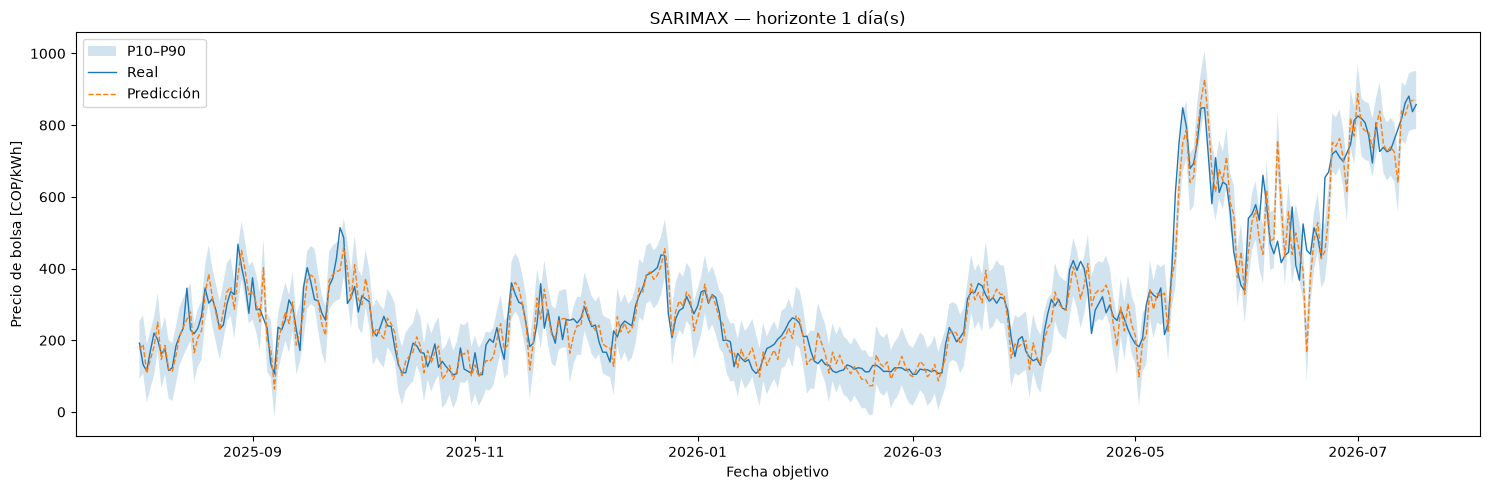

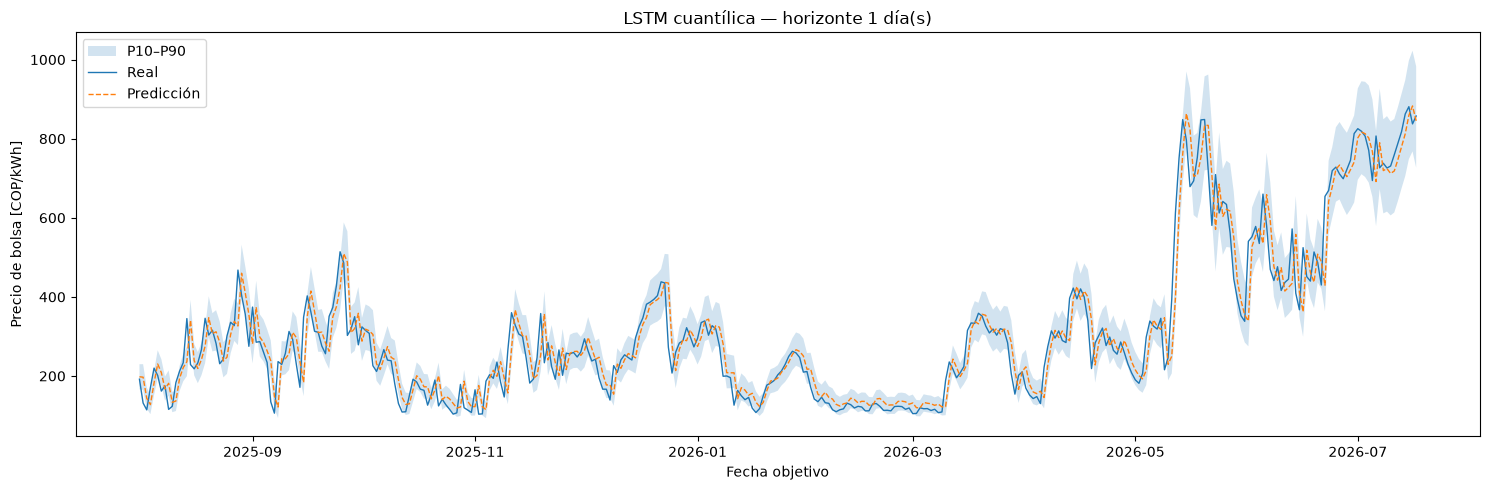

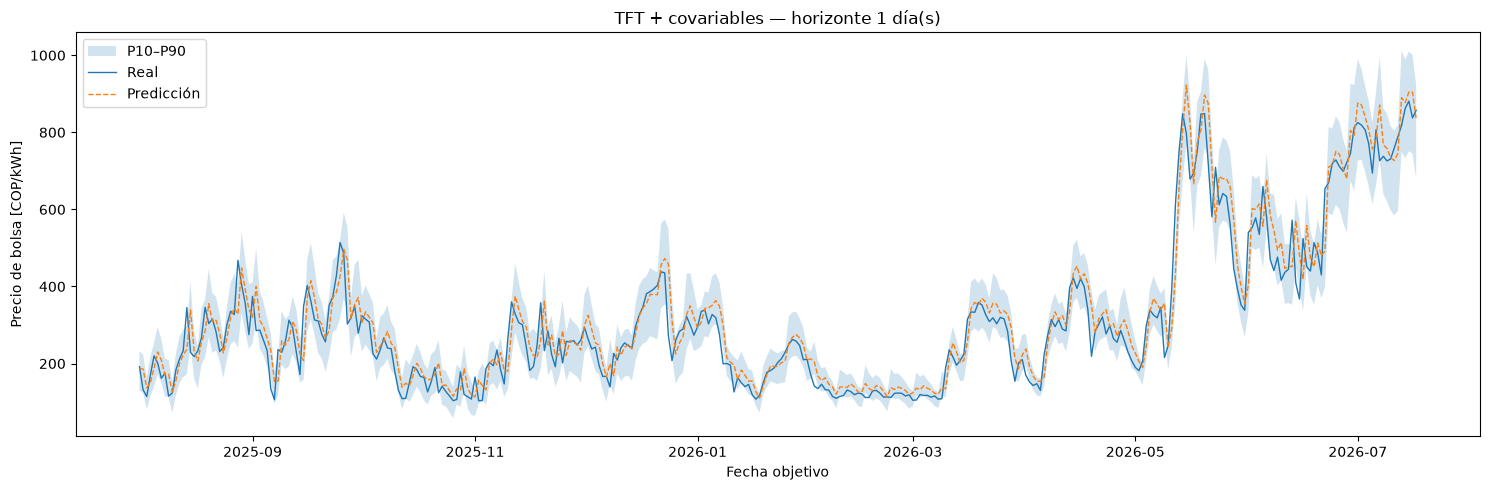

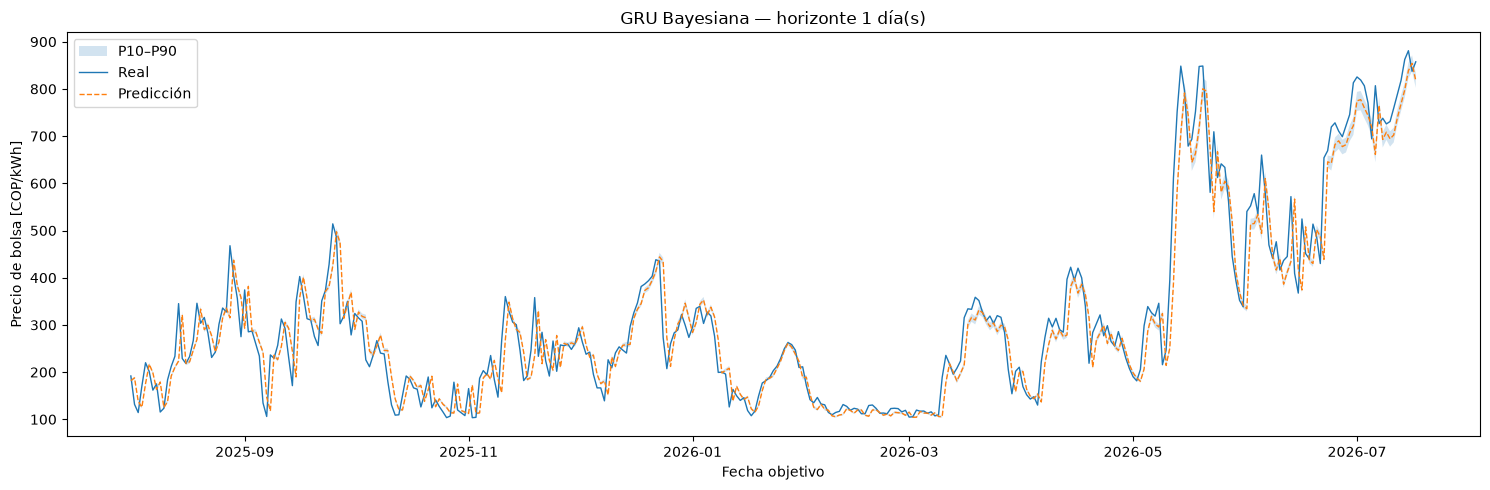

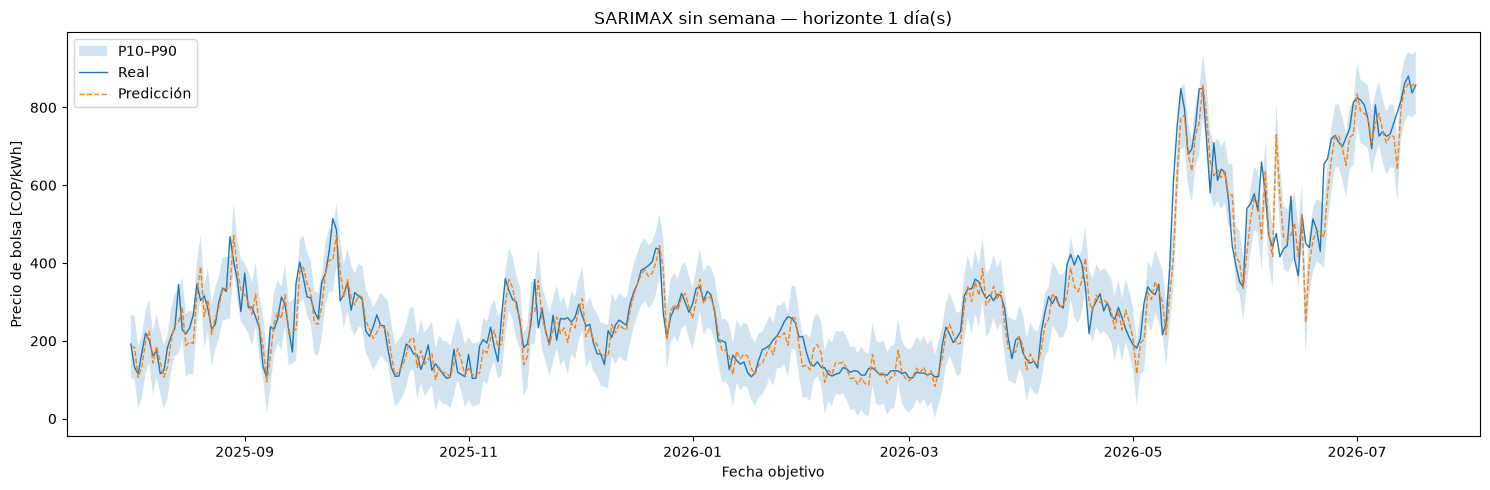

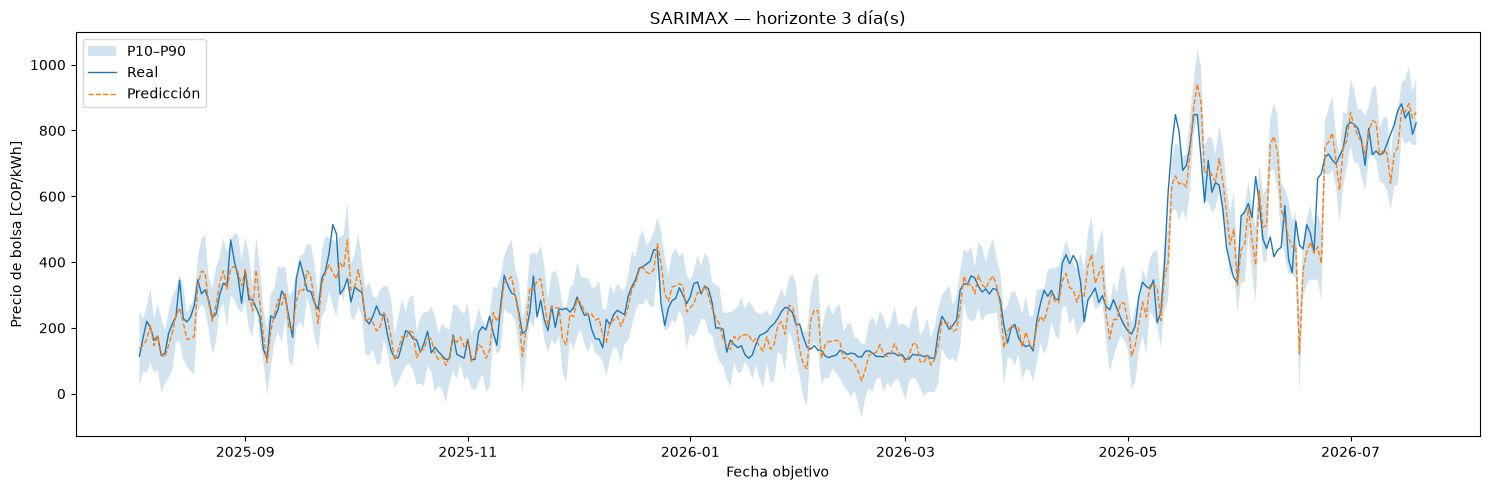

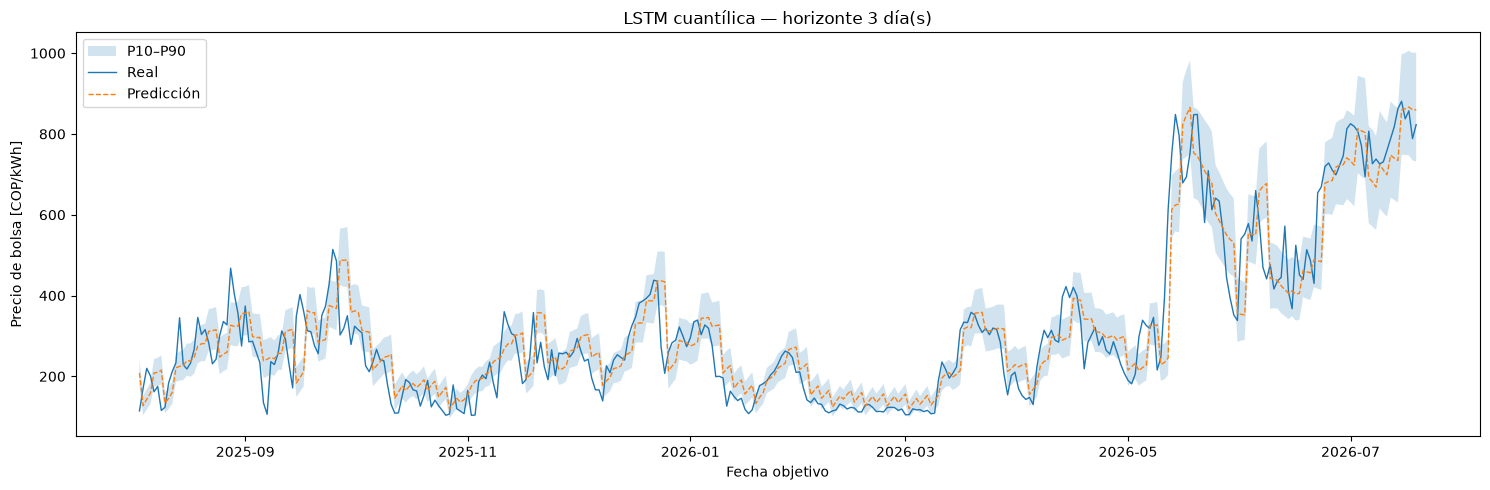

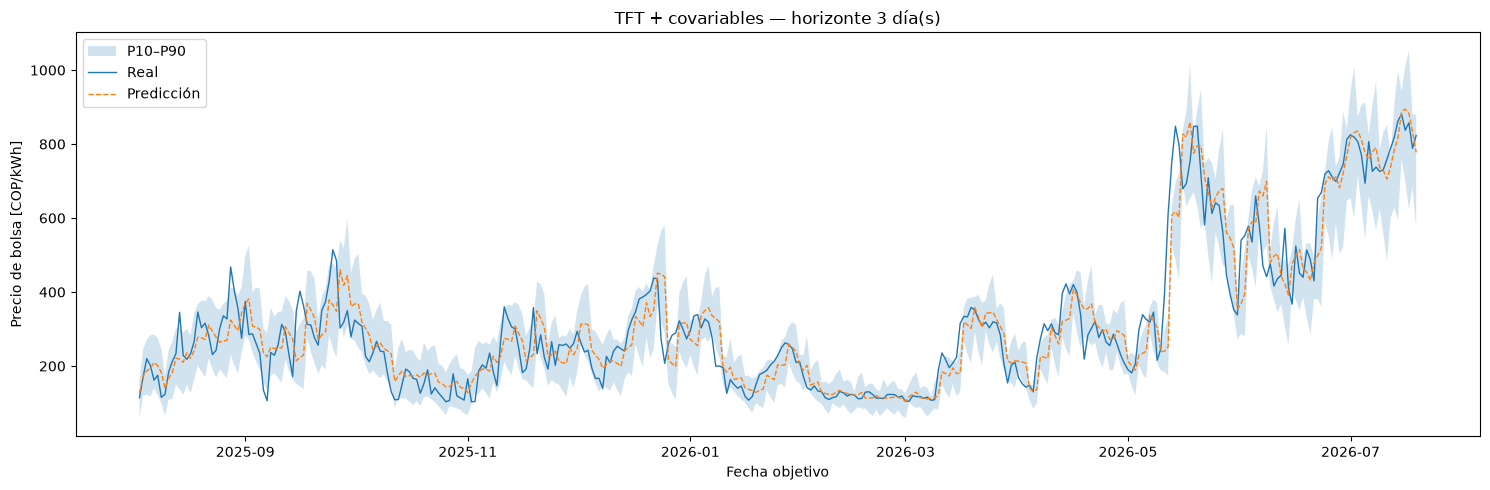

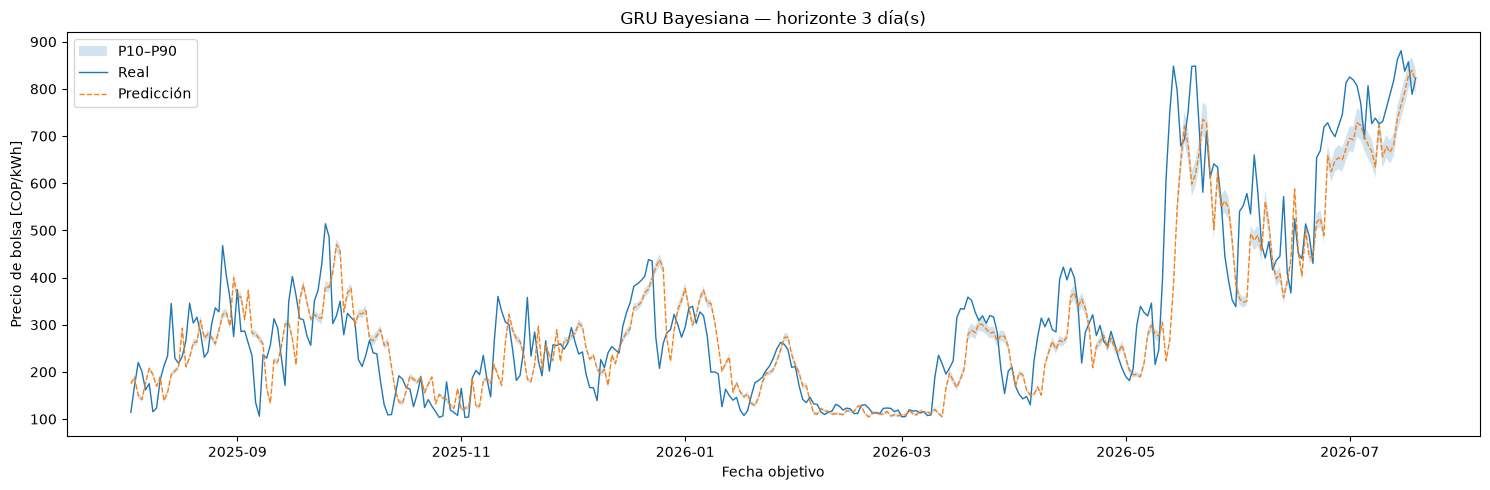

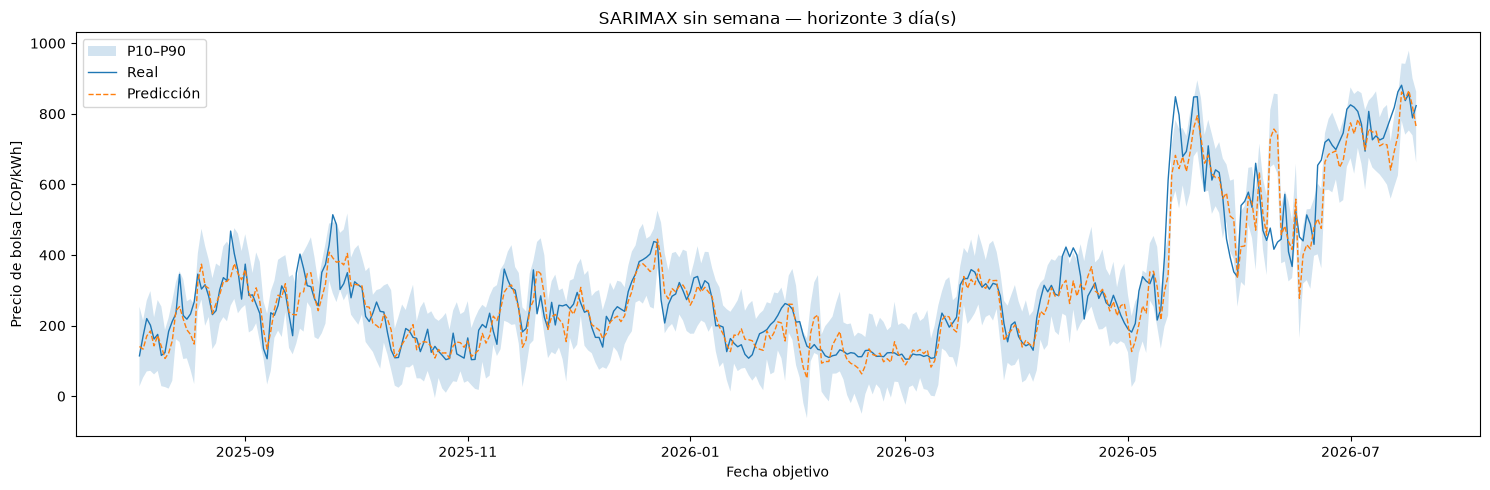

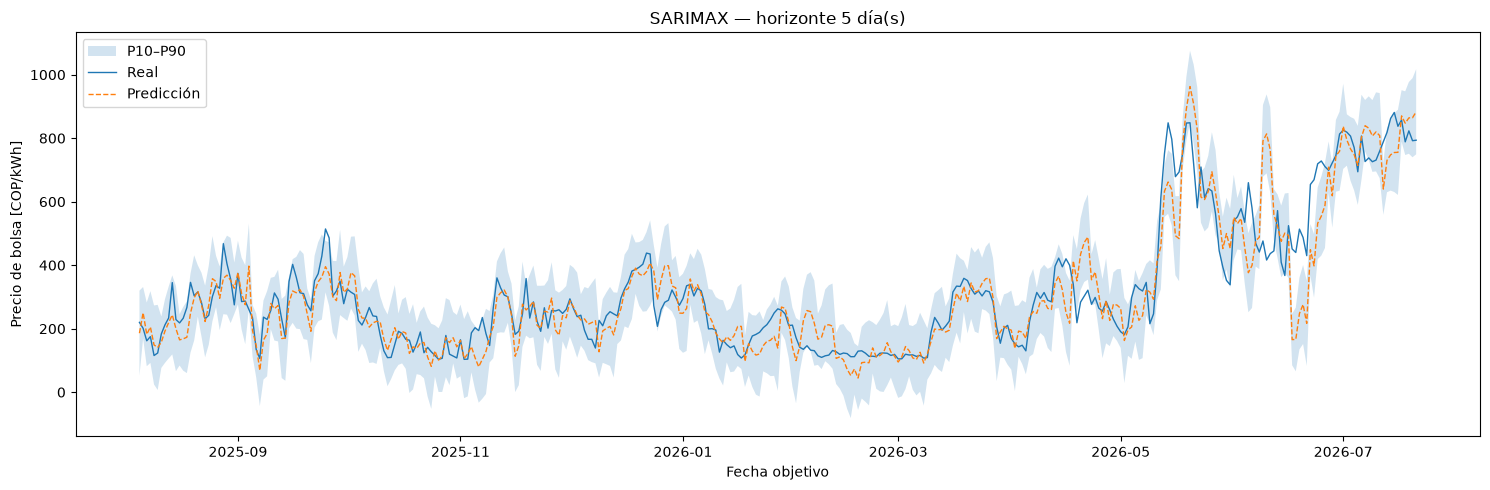

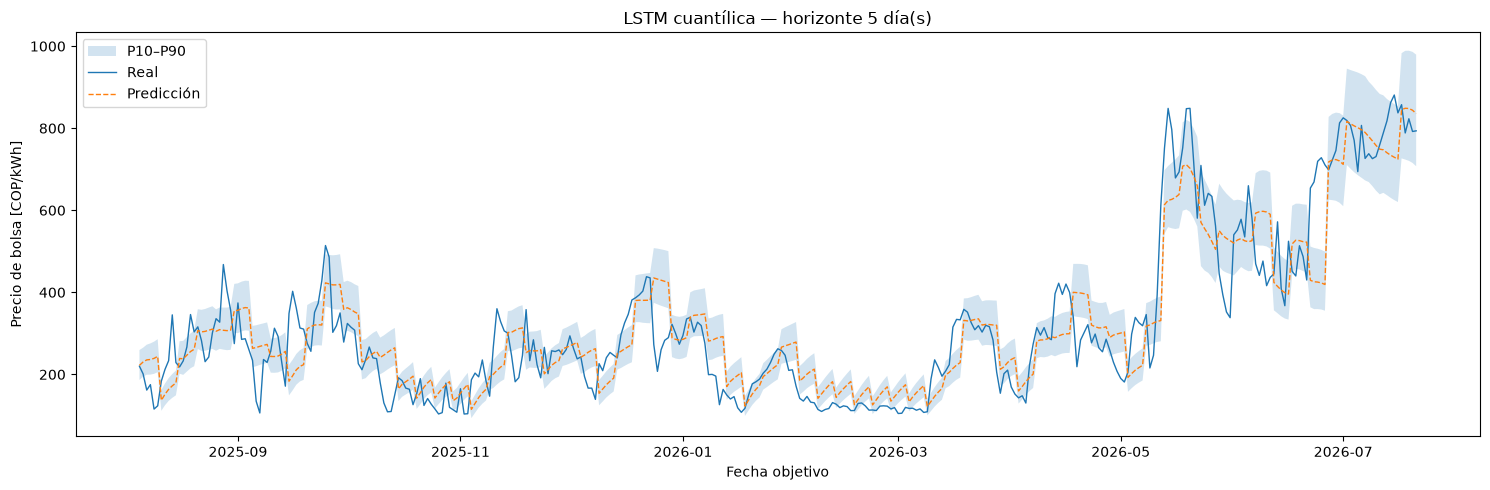

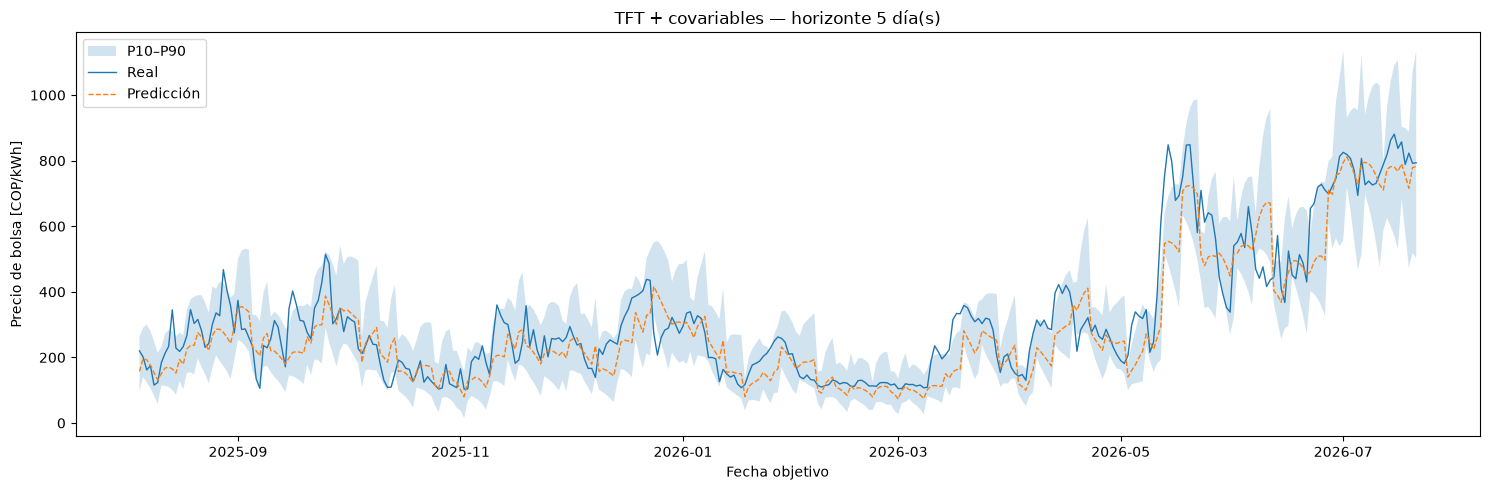

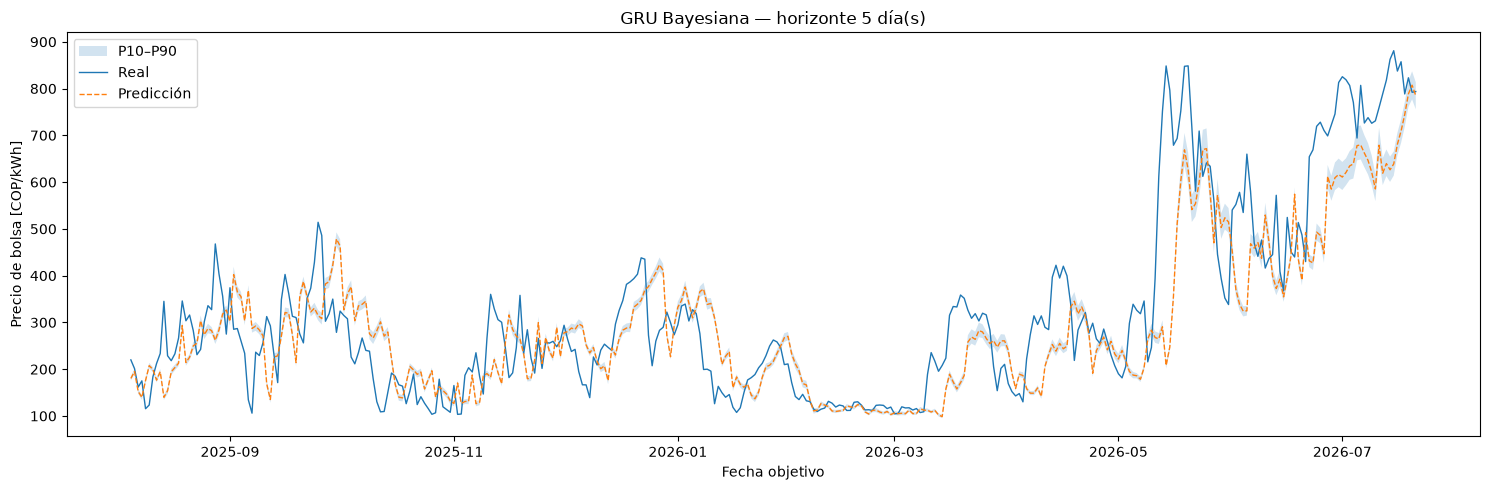

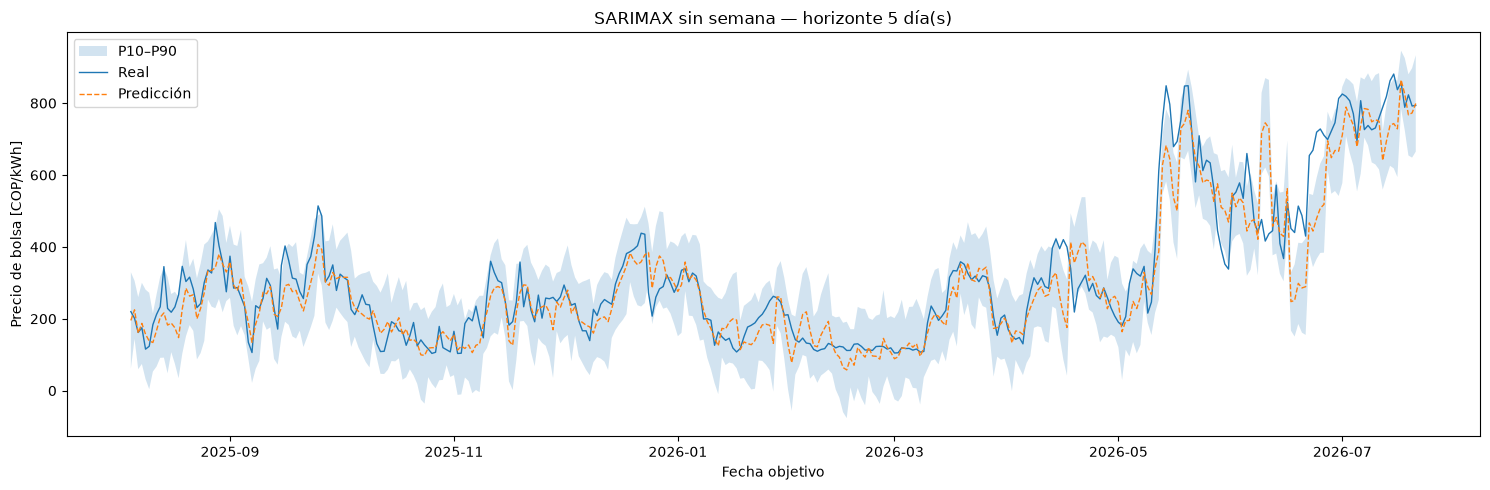

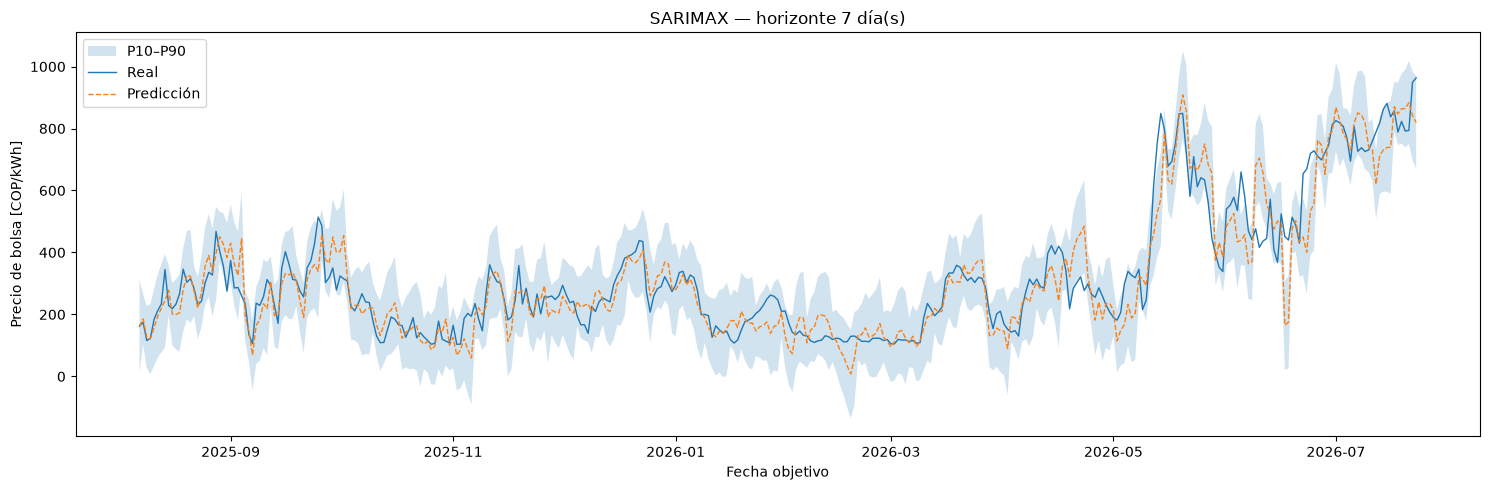

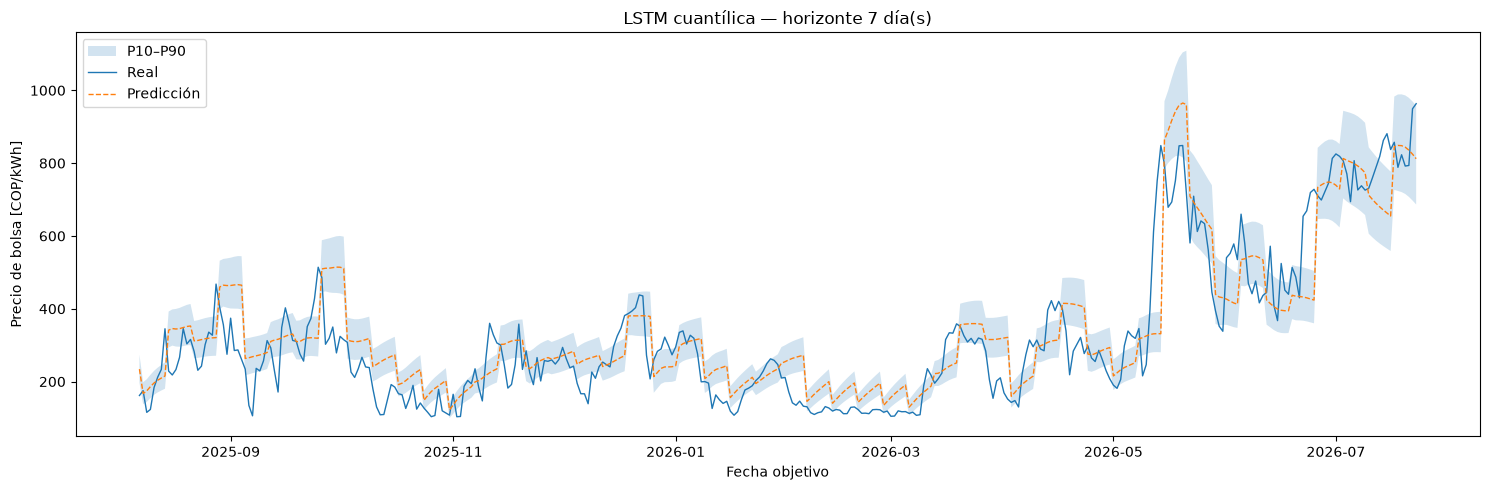

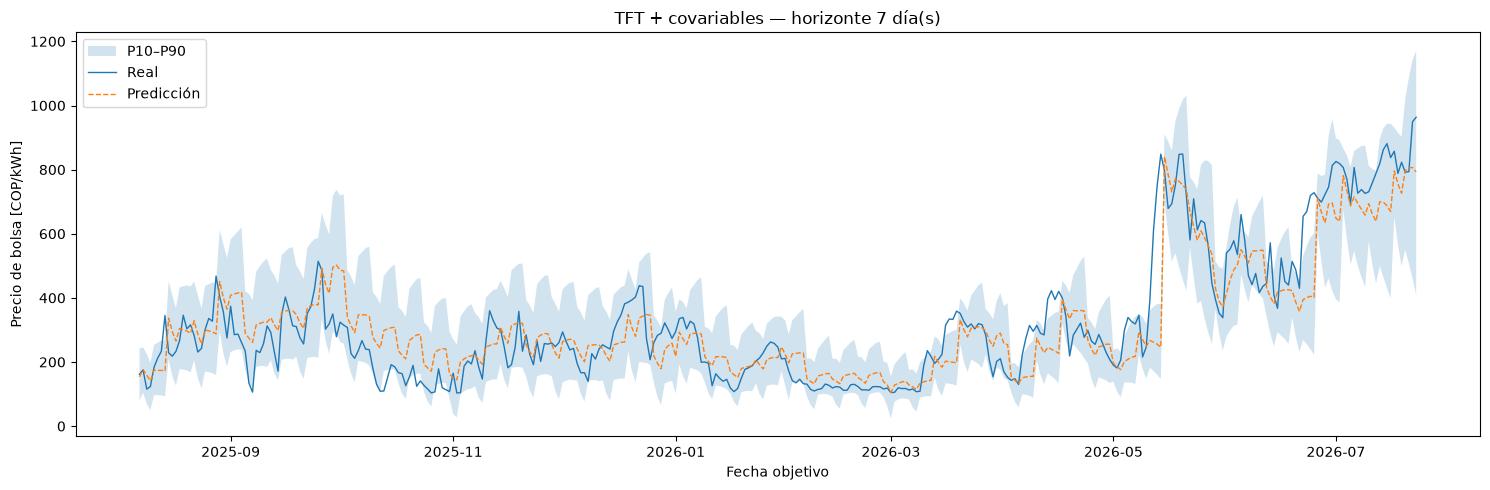

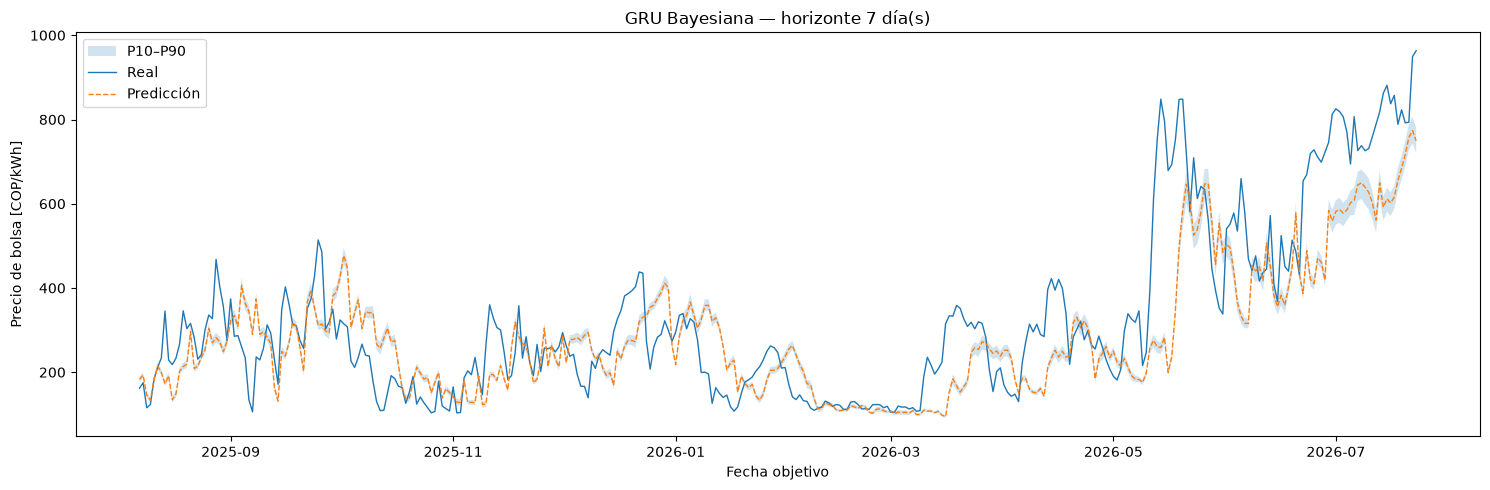

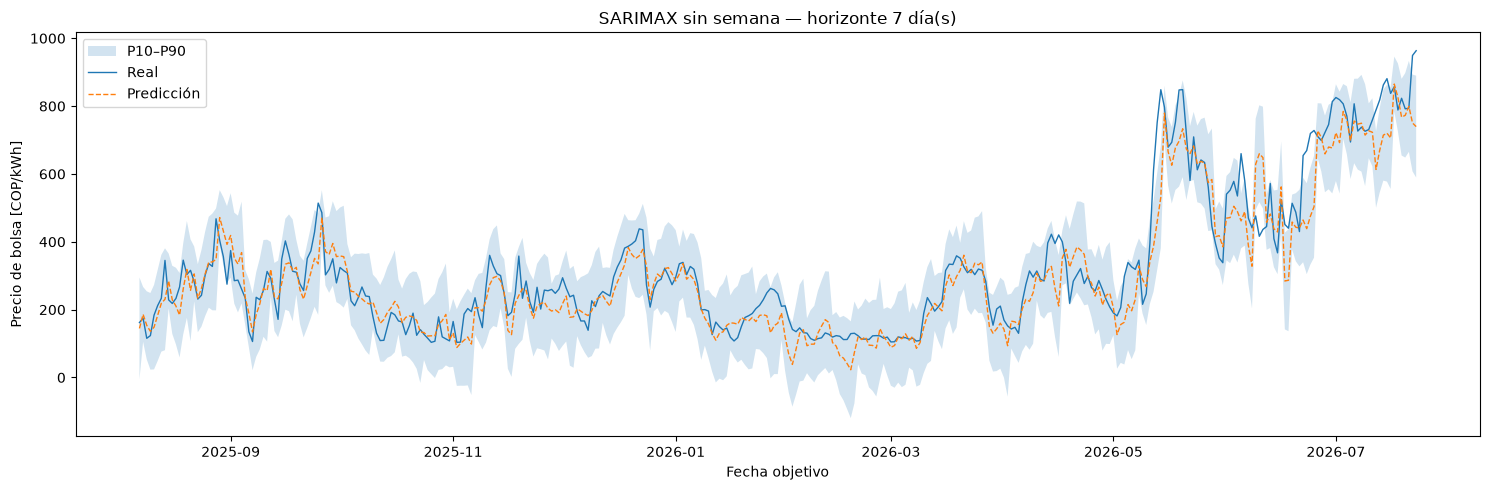

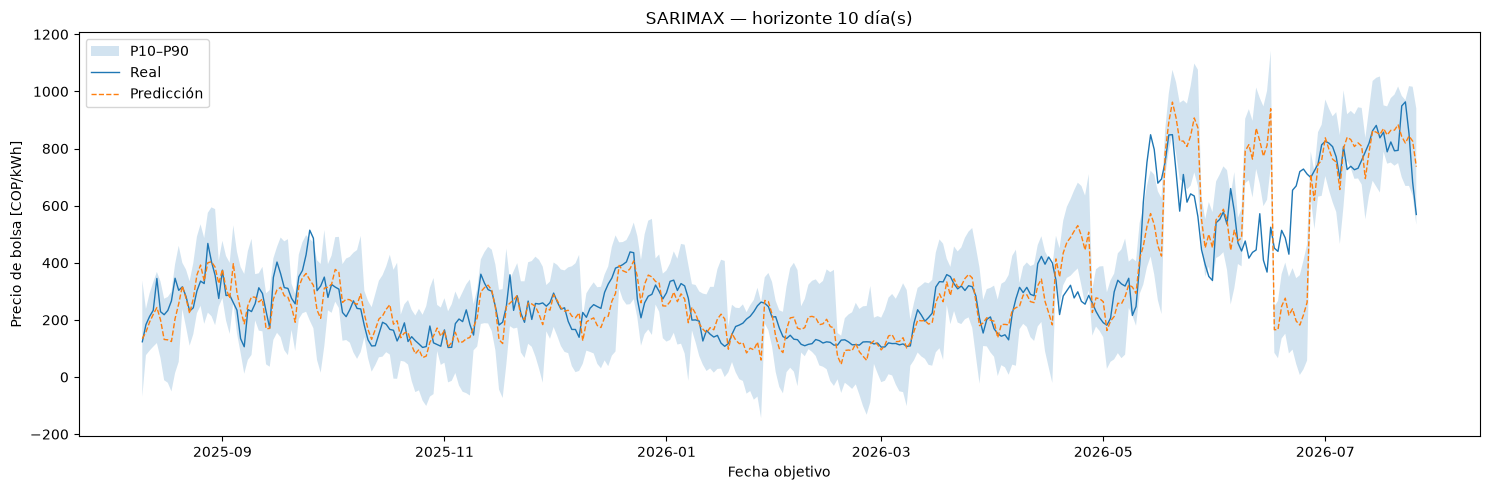

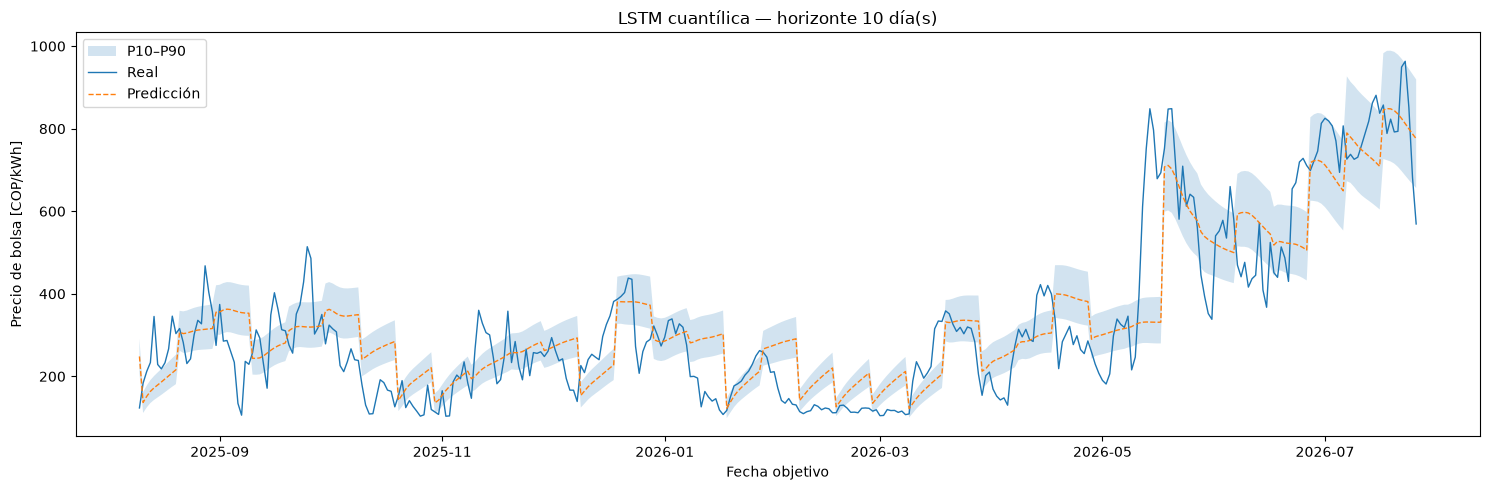

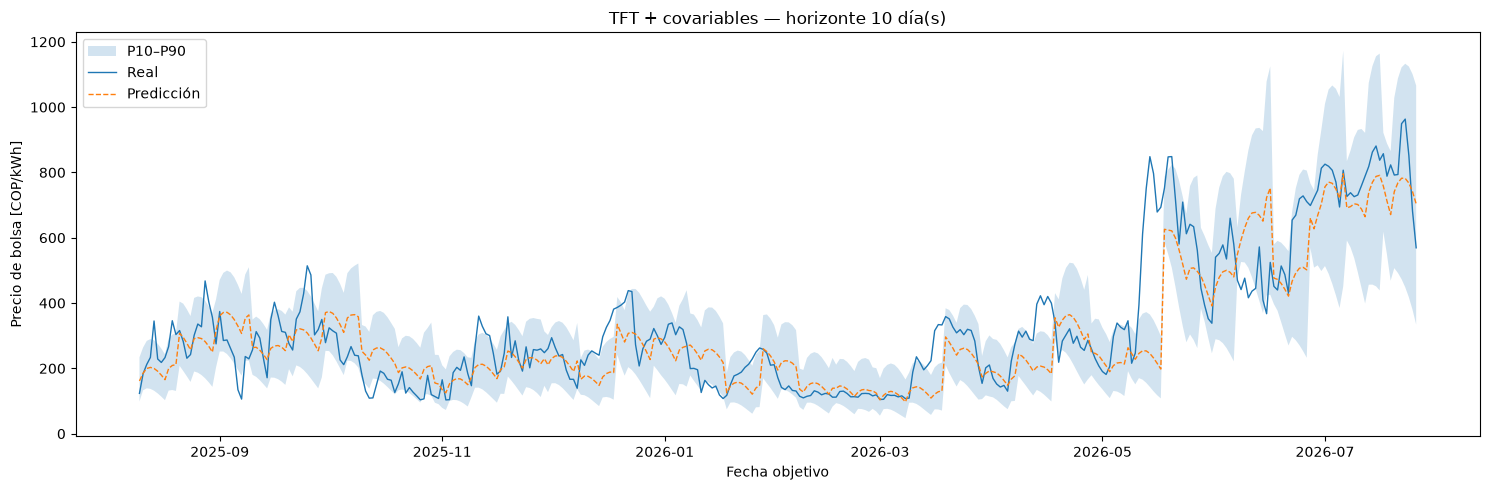

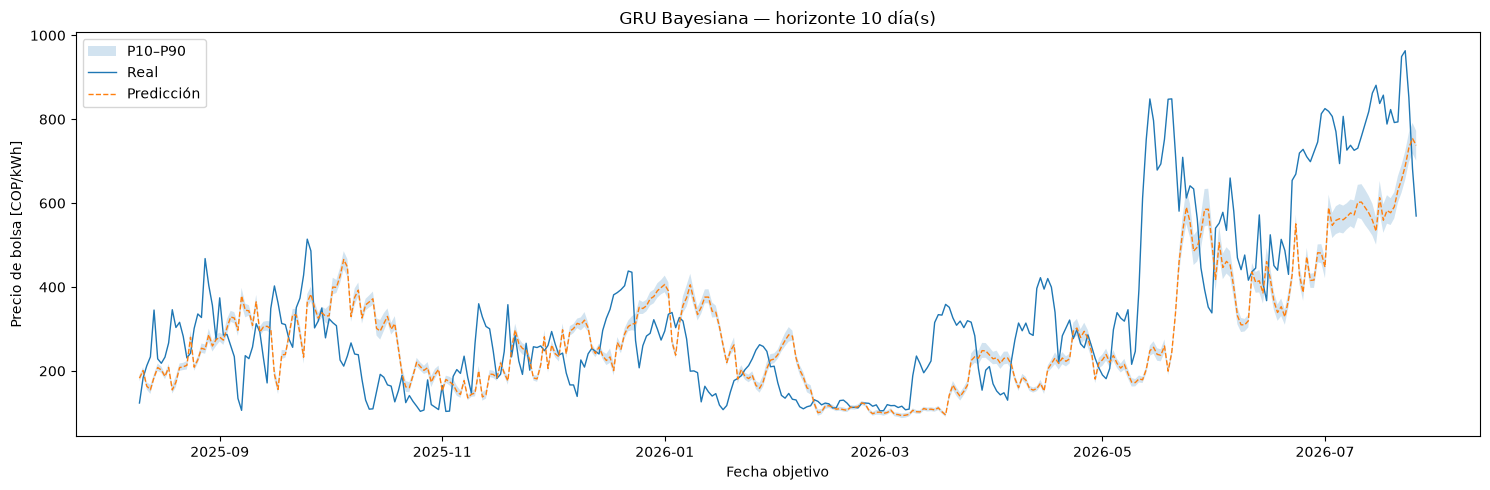

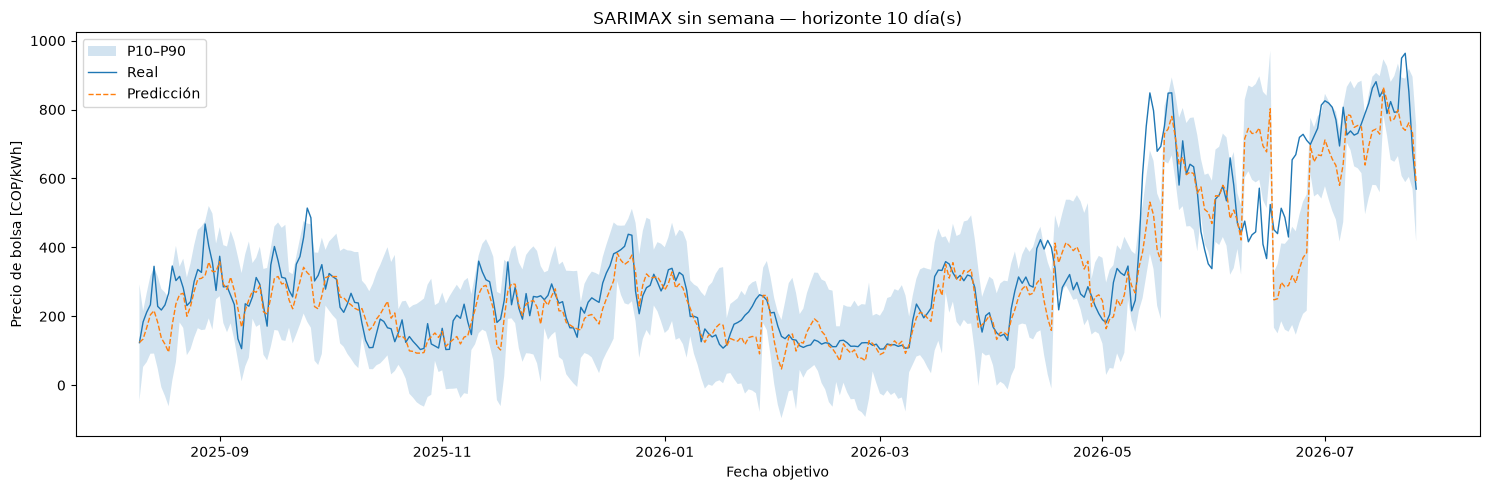

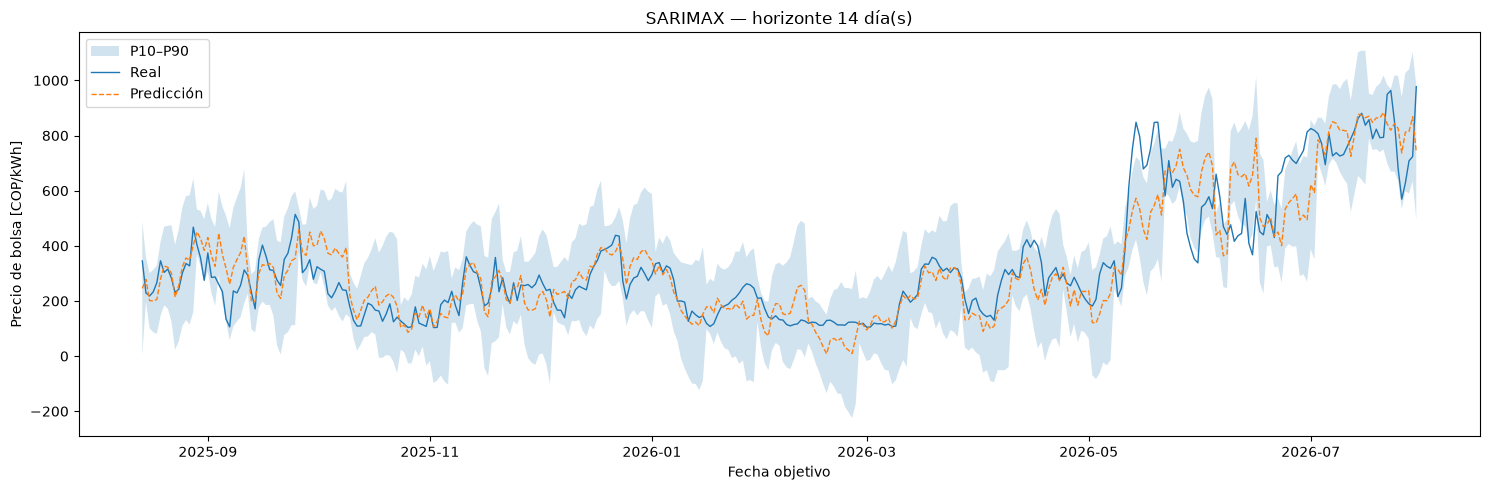

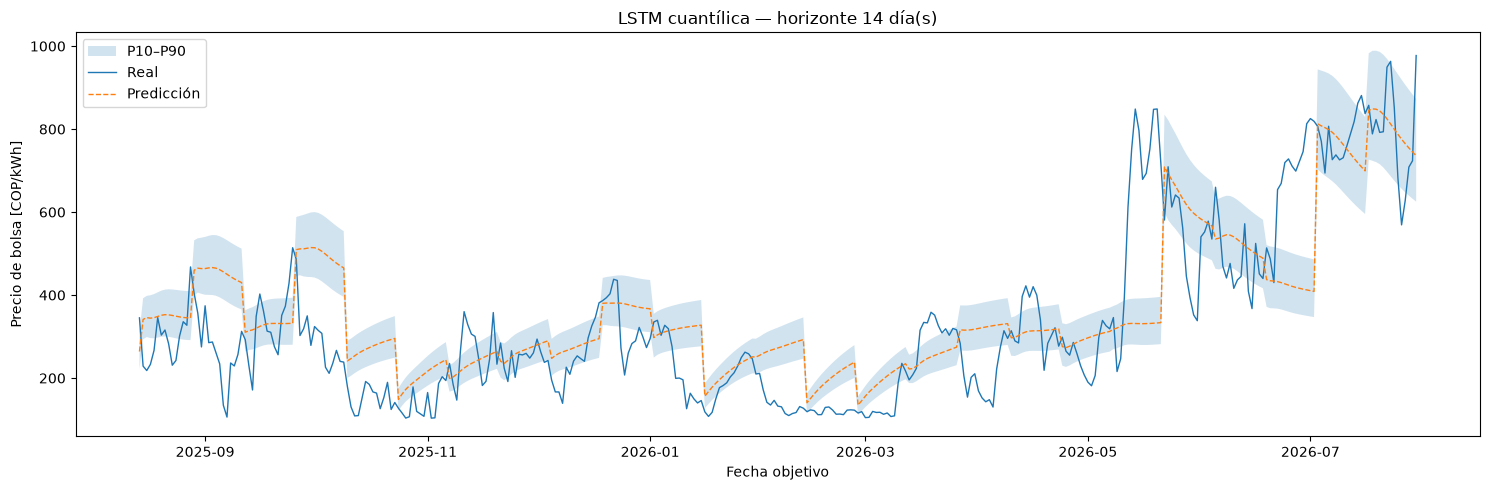

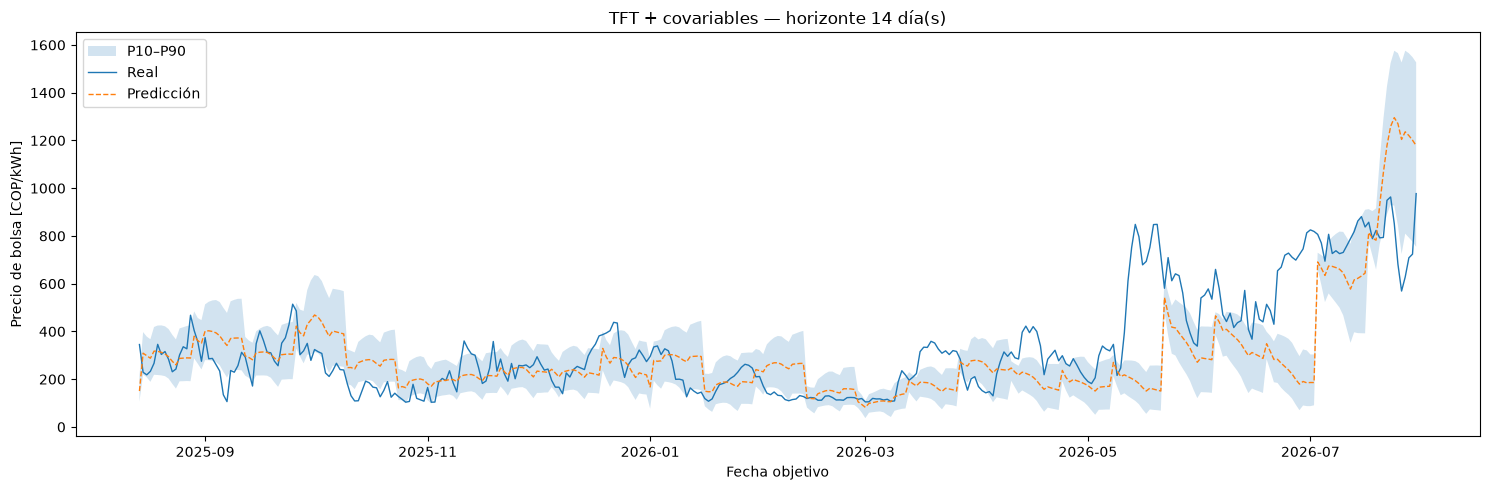

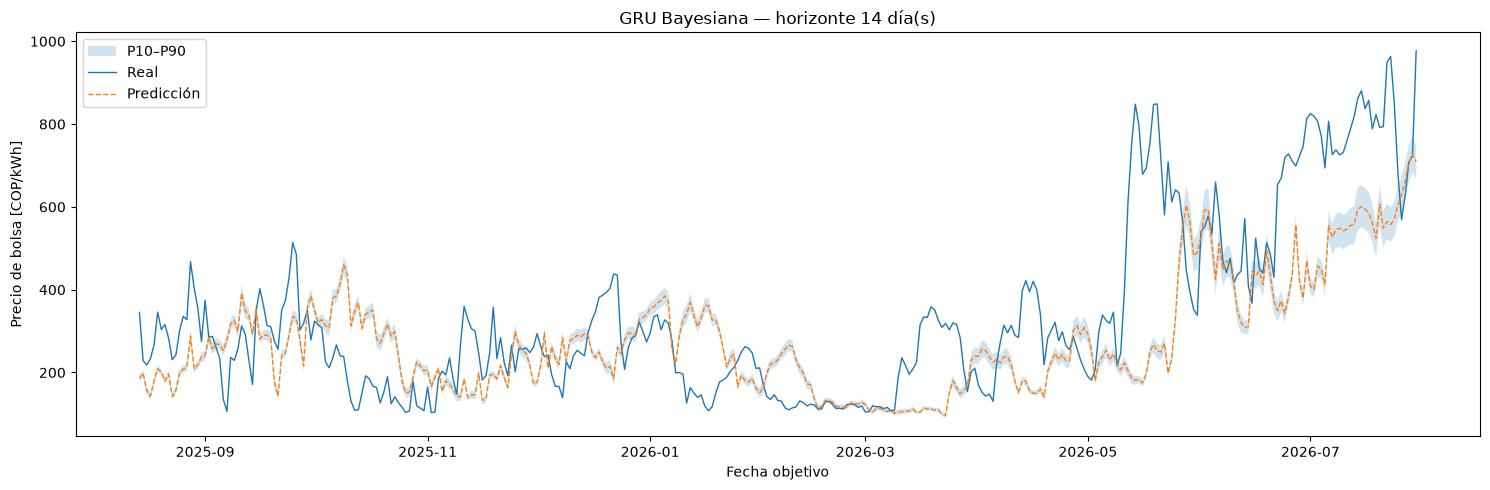

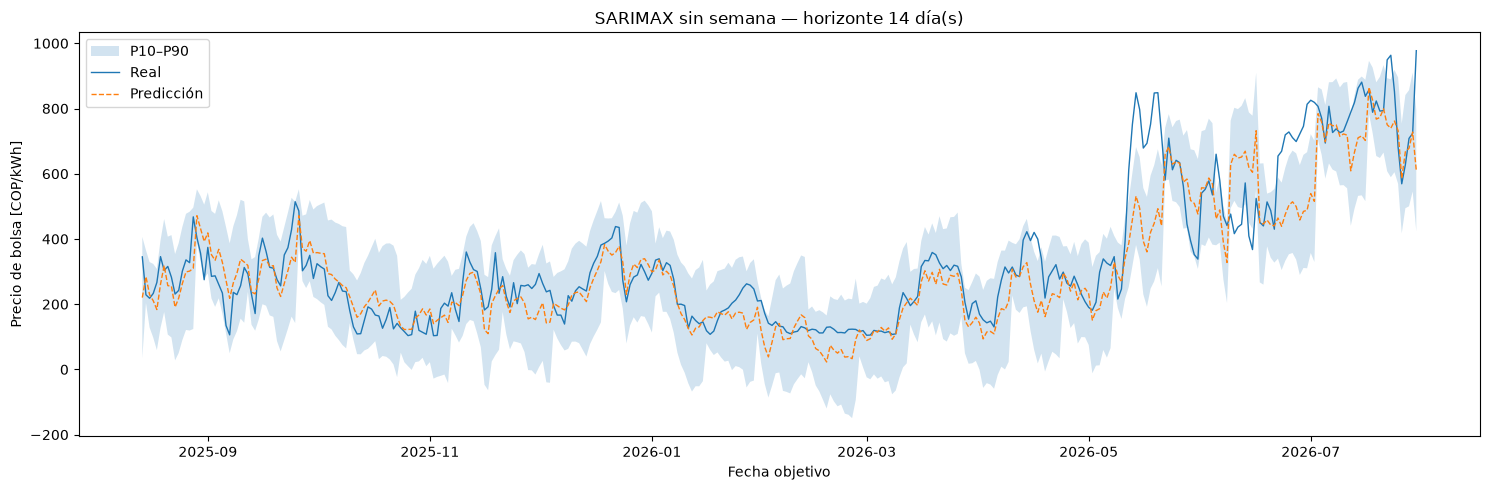

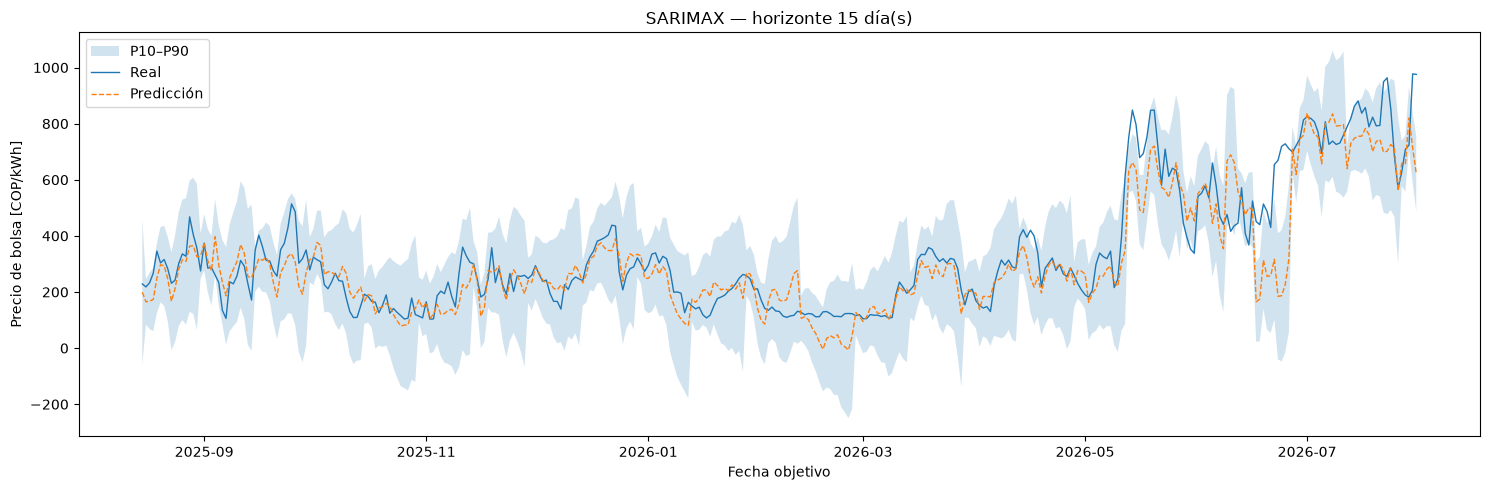

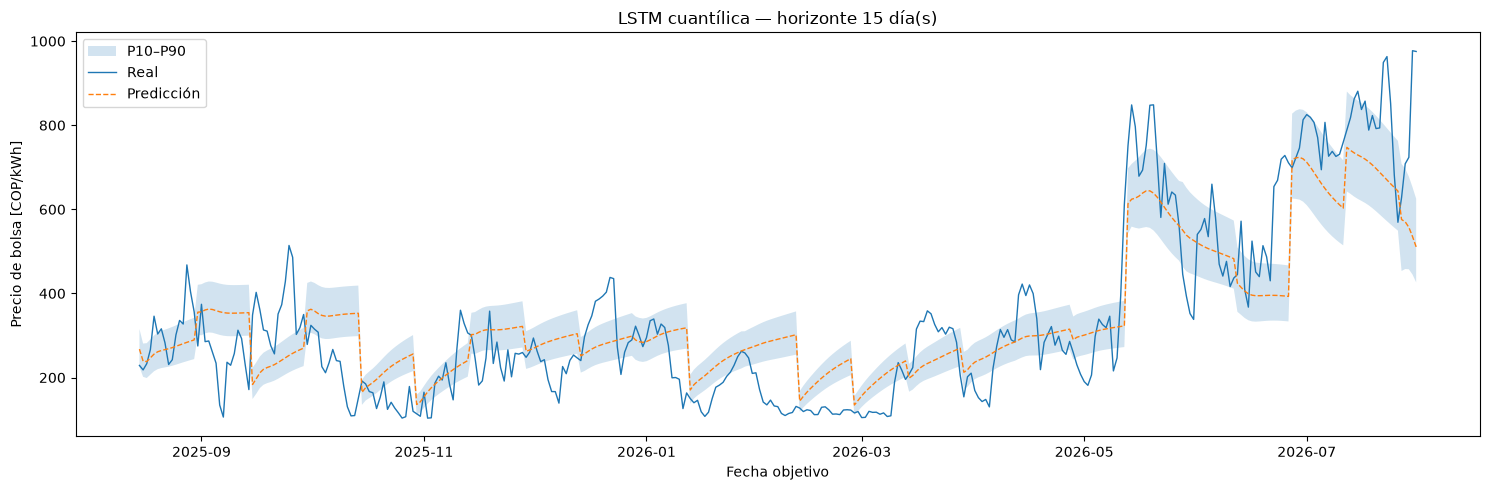

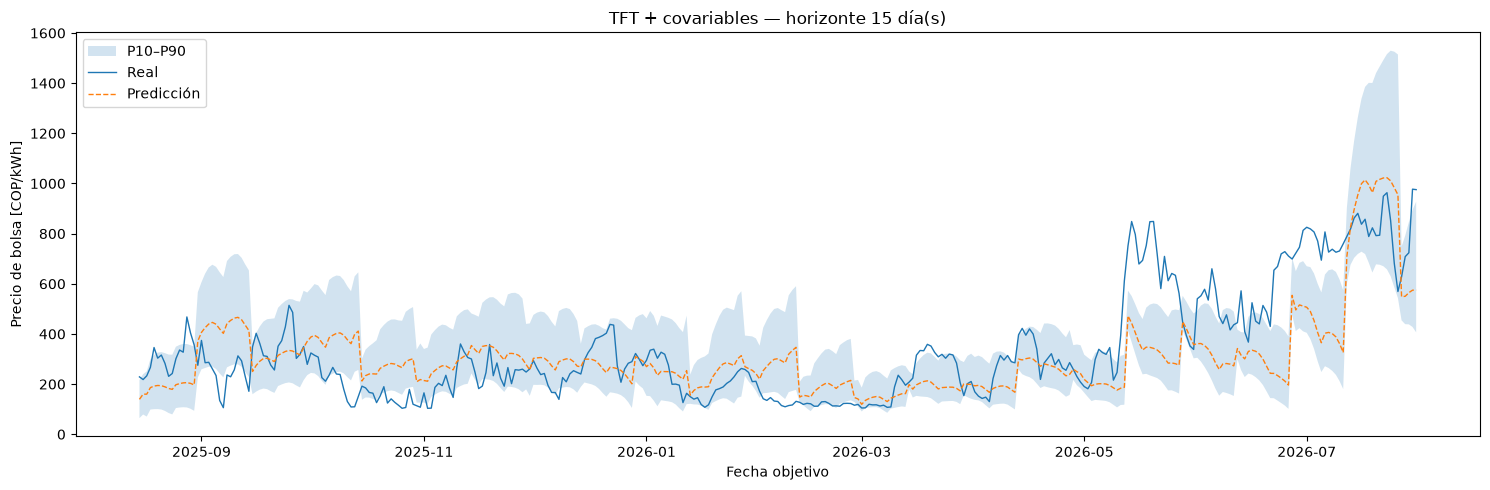

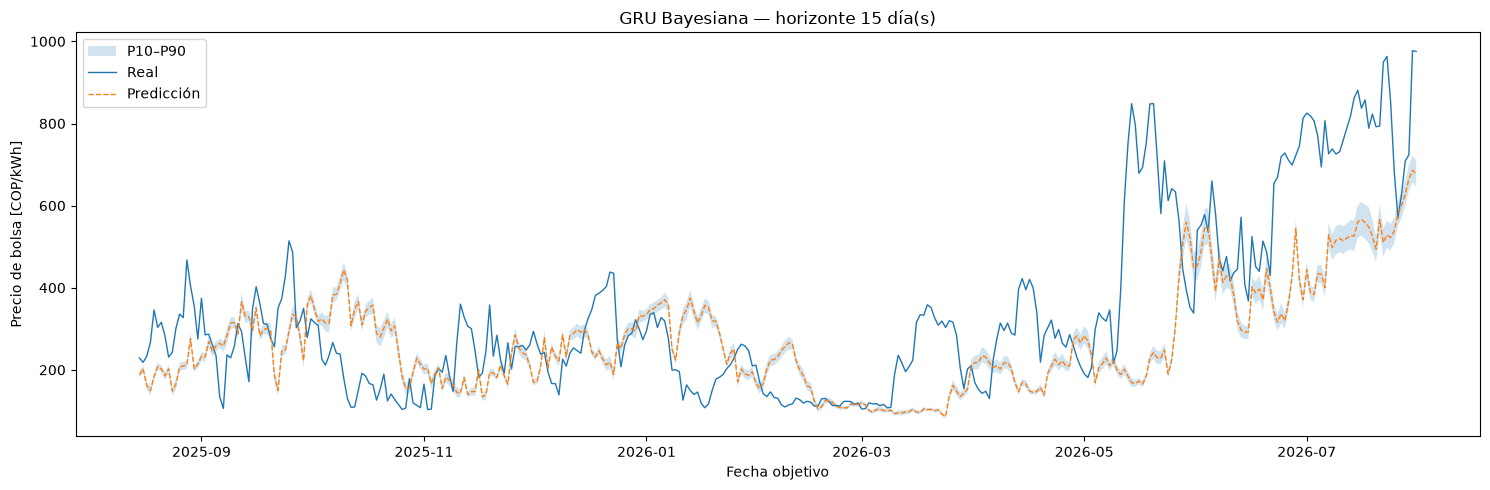

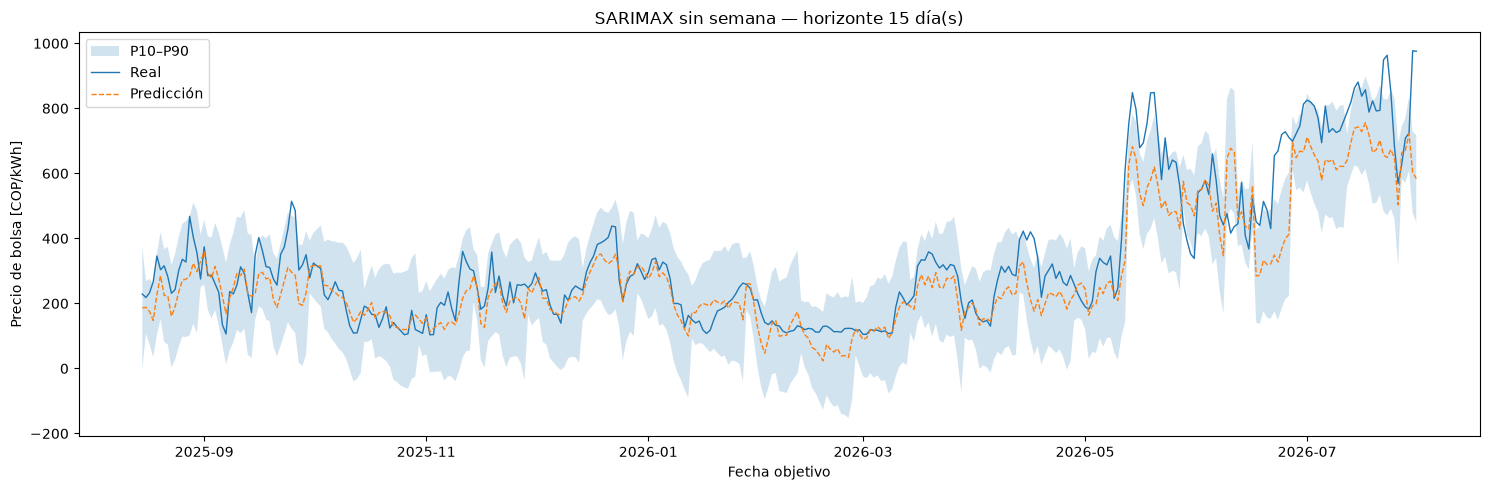

In [14]:
for h in [1, 3, 5, 7, 10, 14, 15]:
    for modelo in ["SARIMAX","LSTM cuantílica","TFT + covariables","GRU Bayesiana", "SARIMAX sin semana"]:
        key=(modelo,h)
        if key not in resultados_comunes:
            continue
        z=resultados_comunes[key]
        plt.figure(figsize=(15,5))
        plt.fill_between(z.index,z.p10,z.p90,alpha=.20,label="P10–P90")
        plt.plot(z.index,z.real,label="Real",linewidth=1)
        plt.plot(z.index,z.pred,"--",label="Predicción",linewidth=1)
        plt.title(f"{modelo} — horizonte {h} día(s)")
        plt.ylabel("Precio de bolsa [COP/kWh]")
        plt.xlabel("Fecha objetivo")
        plt.legend()
        plt.tight_layout()
        plt.show()

## 9. Comparación puntual conjunta

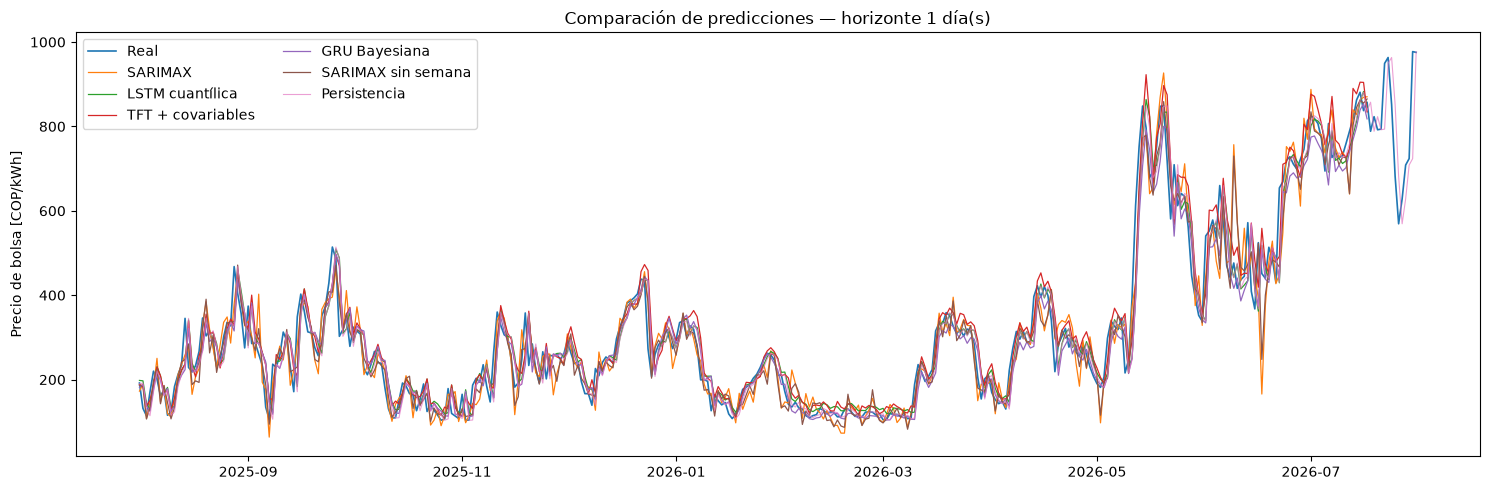

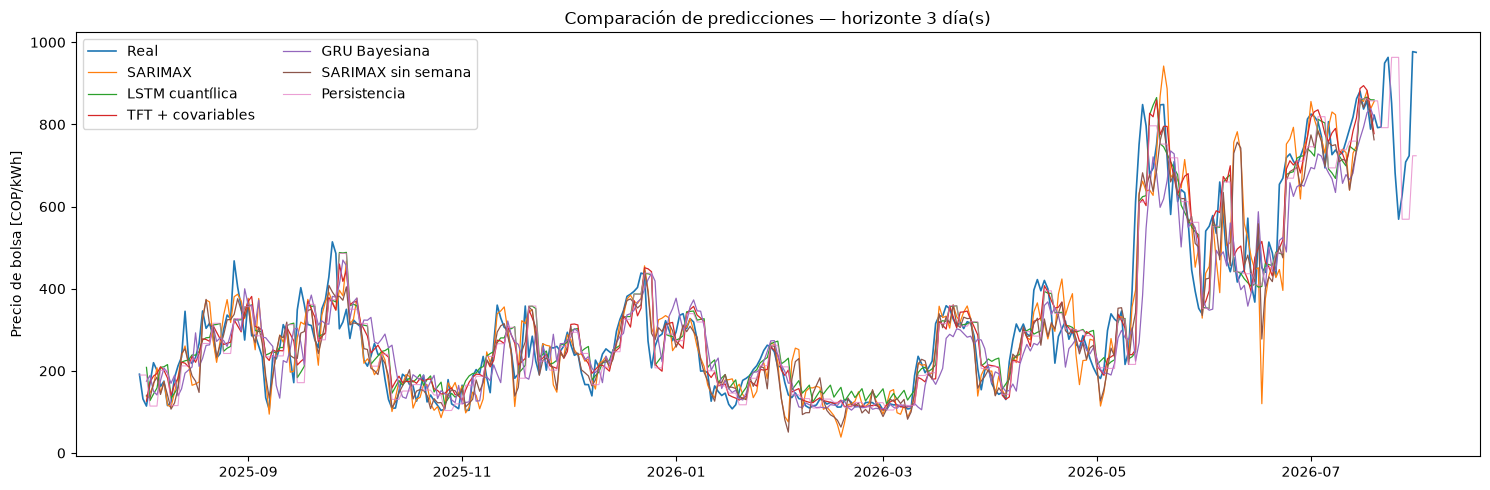

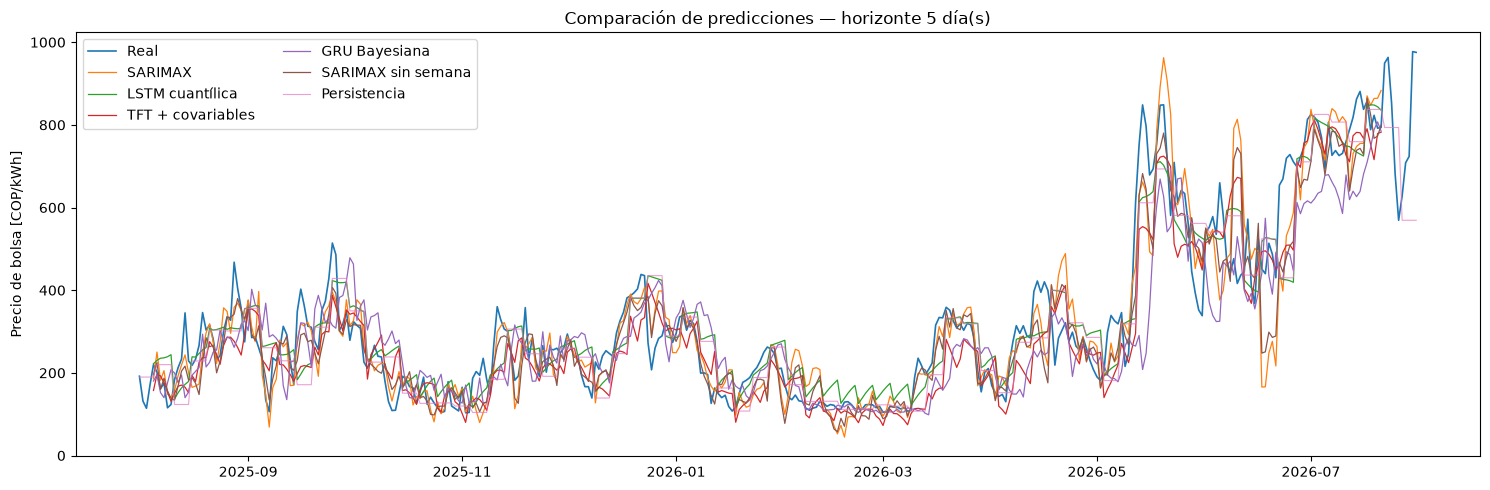

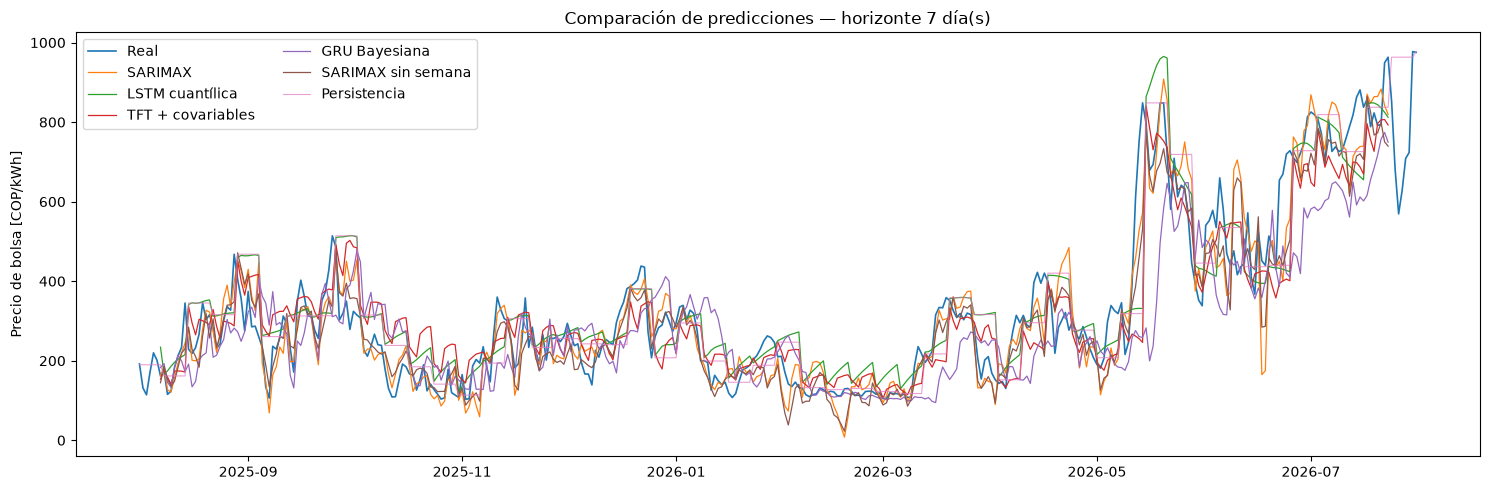

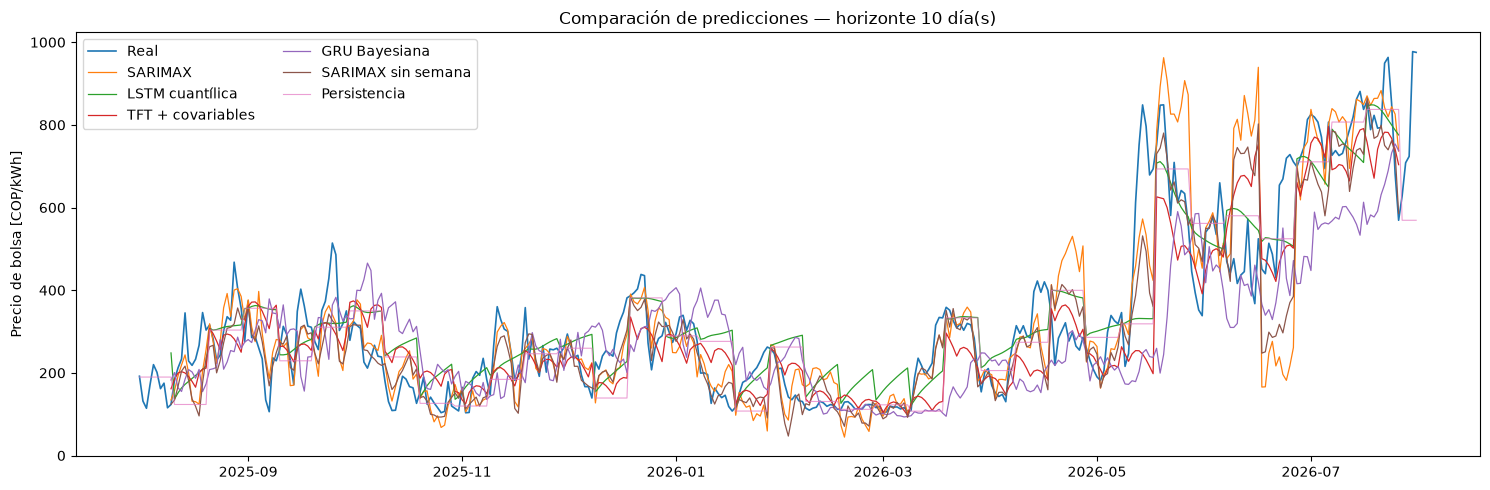

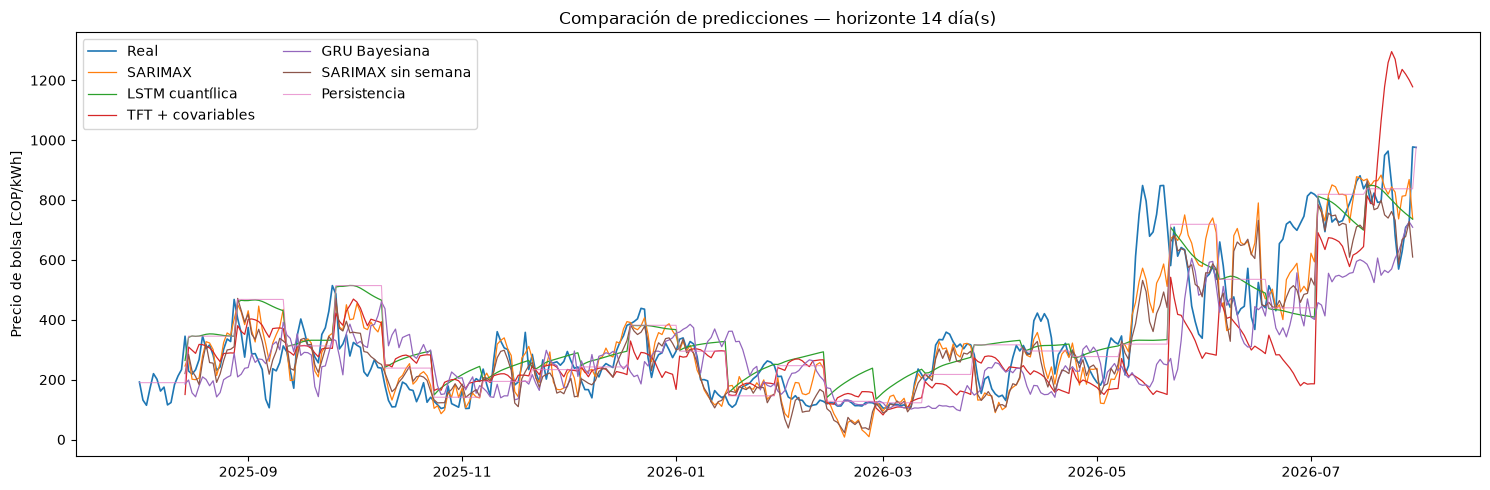

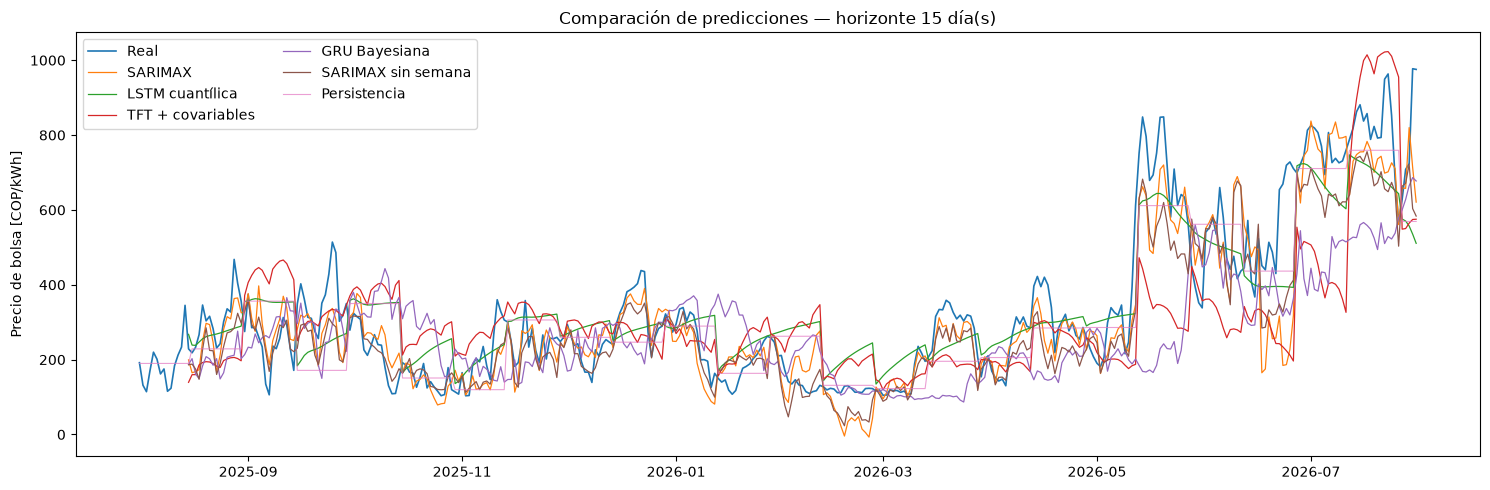

In [15]:
for h in [1, 3, 5, 7, 10, 14, 15]:
    plt.figure(figsize=(15,5))
    plt.plot(test_data.index,test_data.precio_bolsa if hasattr(test_data,'precio_bolsa') else test_data,
             label="Real",linewidth=1.2)
    for modelo in ["SARIMAX","LSTM cuantílica","TFT + covariables","GRU Bayesiana", "SARIMAX sin semana"]:
        if (modelo,h) in resultados_comunes:
            z=resultados_comunes[(modelo,h)]
            plt.plot(z.index,z.pred,label=modelo,linewidth=.9)
    p=persistencia[h]
    plt.plot(p.index,p.values,label="Persistencia",linewidth=.8,alpha=.7)
    plt.title(f"Comparación de predicciones — horizonte {h} día(s)")
    plt.ylabel("Precio de bolsa [COP/kWh]")
    plt.legend(ncol=2)
    plt.tight_layout()
    plt.show()

## 10. Calibración UCT

In [16]:
if UCT_OK:
    for h in [1, 3, 5, 7, 10, 14, 15]:
        for modelo in ["SARIMAX","LSTM cuantílica","TFT + covariables","GRU Bayesiana", "SARIMAX sin semana"]:
            if (modelo,h) not in resultados_comunes:
                continue
            z=resultados_comunes[(modelo,h)]
            try:
                uct.viz.plot_calibration(
                    z.pred.to_numpy(),z["std"].to_numpy(),z.real.to_numpy()
                )
                plt.title(f"Calibración UCT — {modelo} — h={h}")
                plt.tight_layout()
                plt.show()
            except Exception as e:
                print(f"No se pudo dibujar calibración {modelo} h={h}: {e}")
else:
    print("Instala uncertainty-toolbox para generar estas gráficas.")

Instala uncertainty-toolbox para generar estas gráficas.


## 11. Tablas, exportaciones y análisis de estacionalidad

Se exportan las 15 evaluaciones de cada modelo y las curvas completas. Se destacan h=7 y h=14, y se compara el SARIMAX estacional con el no estacional y con la persistencia semanal. La mejora estacional por sí sola no prueba causalidad; requiere corroboración con validación y orígenes idénticos.

RANKING PUNTUAL


,Modelo,Horizonte,MAE,RMSE,MAPE (%),sMAPE (%),R²,Sesgo
4,SARIMAX sin semana,1,33.1620,48.0352,12.2996,12.4208,0.9372,-7.2458
2,TFT + covariables,1,39.2719,53.6478,14.8066,13.7647,0.9216,15.8793
0,SARIMAX,1,37.8263,54.0135,14.0967,14.1388,0.9206,-2.3379
3,GRU Bayesiana,1,37.9411,55.0100,13.3722,13.3177,0.9176,-8.9152
1,LSTM cuantílica,1,39.6034,55.1499,14.9370,14.3477,0.9172,3.0967
...,...,...,...,...,...,...,...,...
89,Persistencia,15,81.9043,109.6456,29.6386,27.8355,0.7361,-19.7026
71,LSTM cuantílica,15,86.0124,110.4006,35.4516,28.9465,0.7324,1.3827
104,Persistencia semanal,15,104.2760,141.3326,34.8264,33.2487,0.5615,-21.8692
72,TFT + covariables,15,125.9279,167.3469,43.2592,38.6585,0.3852,-26.9420


RANKING / DIAGNÓSTICO PROBABILÍSTICO


,Modelo,Horizonte,Cobertura 80% (%),Ancho P10-P90,Interval score 80%,CRPS,NLL
2,TFT + covariables,1,82.0513,130.5232,173.9415,NaN,NaN
4,SARIMAX sin semana,1,91.7379,161.8360,195.9055,NaN,NaN
1,LSTM cuantílica,1,71.2251,104.3046,203.8504,NaN,NaN
0,SARIMAX,1,89.4587,161.8360,207.7670,NaN,NaN
3,GRU Bayesiana,1,12.2507,12.8566,332.2405,NaN,NaN
...,...,...,...,...,...,...,...
74,SARIMAX sin semana,15,86.6097,298.2404,378.0946,NaN,NaN
70,SARIMAX,15,90.5983,344.2235,414.9162,NaN,NaN
71,LSTM cuantílica,15,39.8860,113.4475,517.2135,NaN,NaN
72,TFT + covariables,15,64.9573,282.3440,565.2207,NaN,NaN


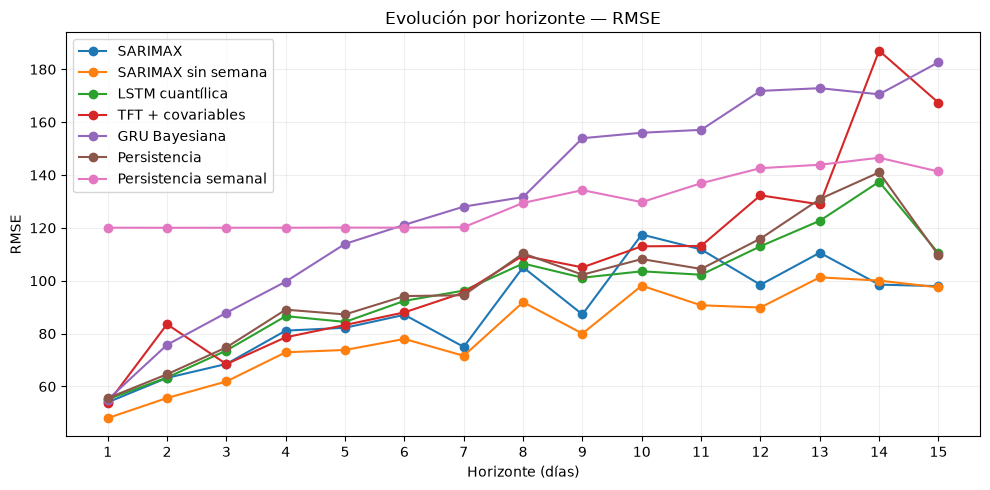

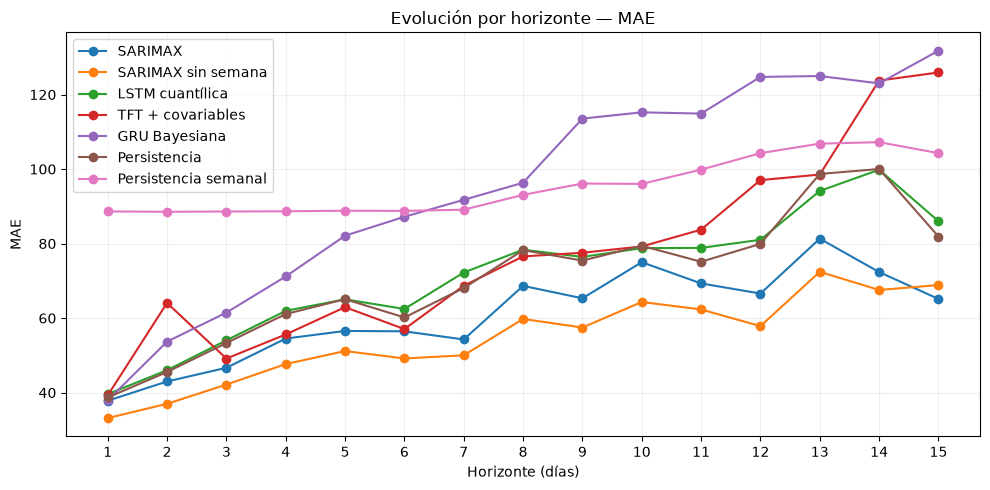

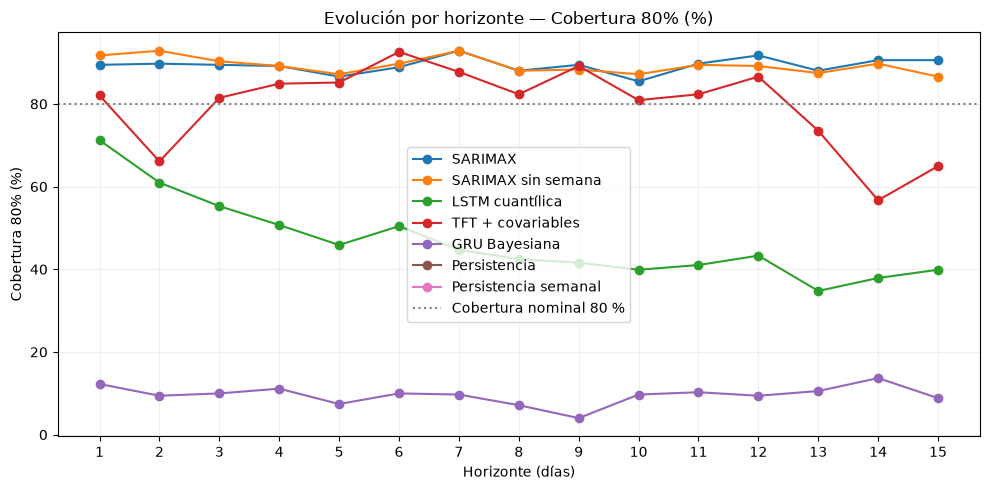

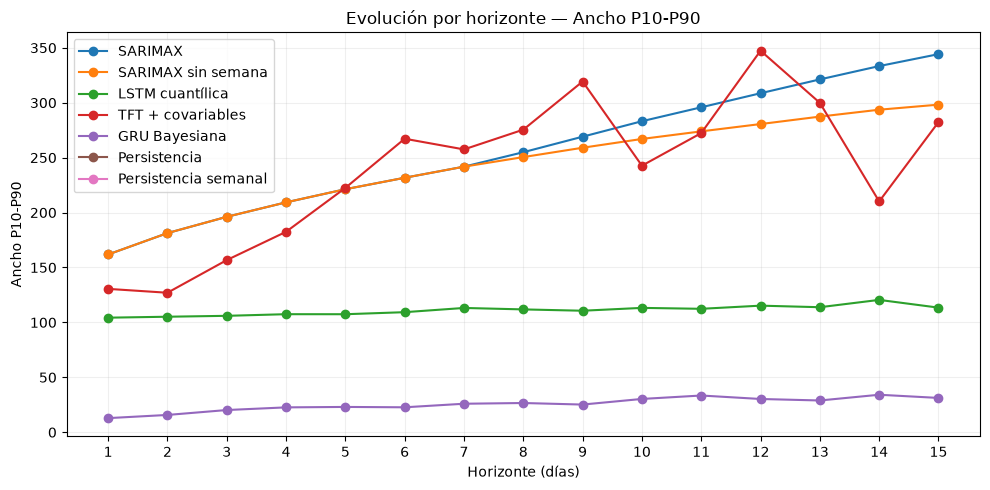

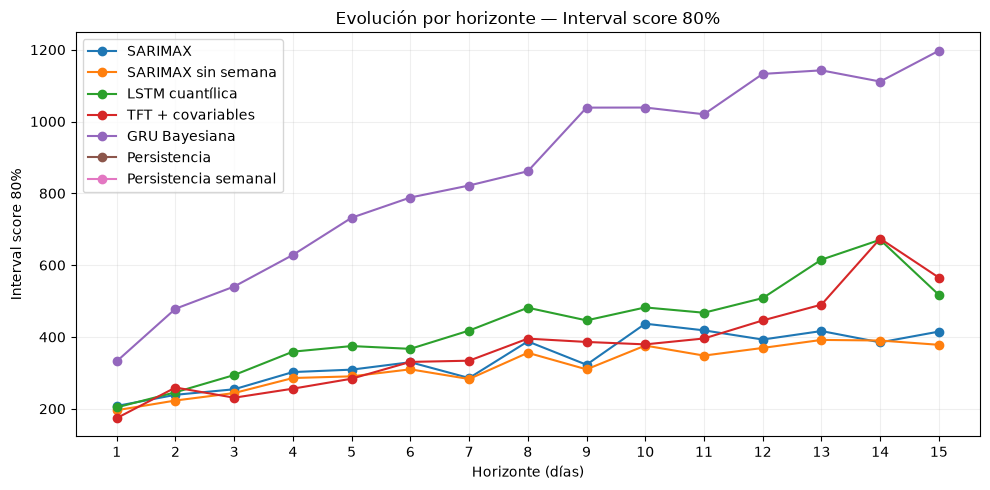

Resultados guardados en: /Users/maguverm/Documents/tesis-bolsa/reports/analisis_horizontes_1_a_15
CONTRASTE DE ESTACIONALIDAD:


Modelo,GRU Bayesiana,LSTM cuantílica,Persistencia,Persistencia semanal,SARIMAX,SARIMAX sin semana,TFT + covariables,Ventaja estacional vs sin semana (%),Ventaja estacional vs persistencia semanal (%)
Horizonte,,,,,,,,,
1,55.010,55.150,55.570,120.073,54.014,48.035,53.648,-12.446,55.016
2,75.768,63.391,64.630,120.040,63.265,55.650,83.558,-13.683,47.297
3,87.887,73.611,74.796,120.053,68.517,61.903,68.459,-10.683,42.928
4,99.672,86.609,89.061,120.060,81.135,72.943,78.622,-11.231,32.421
5,113.948,84.437,87.267,120.114,82.213,73.817,83.266,-11.373,31.554
6,121.158,92.392,94.200,120.084,87.118,77.993,88.047,-11.700,27.452
7,128.037,96.272,94.532,120.271,74.981,71.606,95.529,-4.714,37.656
8,131.658,106.527,110.350,129.449,105.112,91.910,109.522,-14.364,18.801
9,153.926,101.156,102.291,134.278,87.272,80.019,105.063,-9.063,35.007


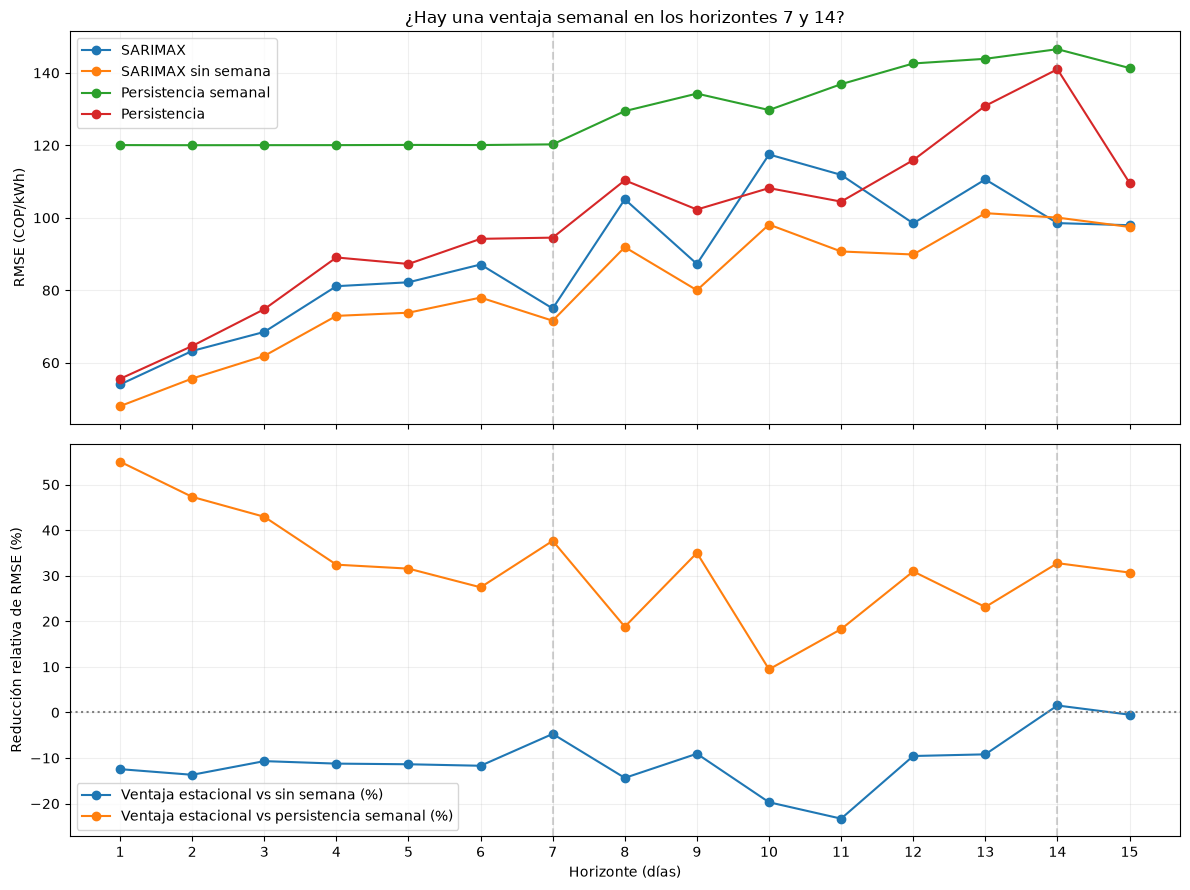

In [17]:
cols_punt=['Modelo','Horizonte','MAE','RMSE','MAPE (%)','sMAPE (%)','R²','Sesgo']
cols_prob=['Modelo','Horizonte','Cobertura 80% (%)','Ancho P10-P90','Interval score 80%',
           'MACE','RMSCE','Sharpness UCT','CRPS','NLL']
print('RANKING PUNTUAL')
display(tabla_final[[c for c in cols_punt if c in tabla_final.columns]].sort_values(['Horizonte','RMSE']).round(4))
prob=tabla_final[~tabla_final.Modelo.isin(['Persistencia','Persistencia semanal'])].copy()
cols=[c for c in cols_prob if c in prob.columns]
criterio='Interval score 80%' if 'Interval score 80%' in cols else 'RMSE'
print('RANKING / DIAGNÓSTICO PROBABILÍSTICO')
display(prob[cols].sort_values(['Horizonte',criterio],na_position='last').round(4))
tabla_final.to_csv(REPORTS/'tabla_comparativa_probabilistica.csv',index=False)
tabla_final.to_parquet(REPORTS/'tabla_comparativa_probabilistica.parquet',index=False)
for (modelo,h),z in resultados_comunes.items():
    nombre=modelo.lower().replace(' ','_').replace('+','mas')
    z.to_parquet(REPORTS/f'pred_{nombre}_h{h}.parquet')
# Curvas de desempeño por horizonte
for metrica in ['RMSE','MAE','Cobertura 80% (%)','Ancho P10-P90','Interval score 80%']:
    fig,ax=plt.subplots(figsize=(10,5))
    for modelo in ['SARIMAX','SARIMAX sin semana','LSTM cuantílica','TFT + covariables','GRU Bayesiana','Persistencia','Persistencia semanal']:
        zz=tabla_final[tabla_final.Modelo.eq(modelo)].sort_values('Horizonte')
        ax.plot(zz.Horizonte,zz[metrica],marker='o',label=modelo)
    if metrica=='Cobertura 80% (%)': ax.axhline(80,color='gray',ls=':',label='Cobertura nominal 80 %')
    ax.set_xticks(HORIZONTES); ax.set_xlabel('Horizonte (días)'); ax.set_ylabel(metrica)
    ax.set_title(f'Evolución por horizonte — {metrica}'); ax.grid(alpha=.2); ax.legend()
    fig.tight_layout()
    fig.savefig(REPORTS/f'curva_{metrica.lower().replace(" ","_").replace("%", "pct")}.png',dpi=180)
    plt.show()
print('Resultados guardados en:',REPORTS)

# Comparación específica de estacionalidad, por horizonte
rmse_h = tabla_final.pivot(index='Horizonte', columns='Modelo', values='RMSE')
rmse_h['Ventaja estacional vs sin semana (%)'] = 100 * (
    rmse_h['SARIMAX sin semana'] - rmse_h['SARIMAX']) / rmse_h['SARIMAX sin semana']
rmse_h['Ventaja estacional vs persistencia semanal (%)'] = 100 * (
    rmse_h['Persistencia semanal'] - rmse_h['SARIMAX']) / rmse_h['Persistencia semanal']
rmse_h.to_csv(REPORTS / 'contraste_estacionalidad_semanal.csv')
print('CONTRASTE DE ESTACIONALIDAD:')
display(rmse_h.round(3))

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
for nombre in ['SARIMAX', 'SARIMAX sin semana', 'Persistencia semanal', 'Persistencia']:
    axes[0].plot(rmse_h.index, rmse_h[nombre], marker='o', label=nombre)
axes[0].set_ylabel('RMSE (COP/kWh)')
axes[0].set_title('¿Hay una ventaja semanal en los horizontes 7 y 14?')
axes[0].legend()
axes[0].grid(alpha=.2)
for nombre in ['Ventaja estacional vs sin semana (%)', 'Ventaja estacional vs persistencia semanal (%)']:
    axes[1].plot(rmse_h.index, rmse_h[nombre], marker='o', label=nombre)
axes[1].axhline(0, color='gray', linestyle=':')
axes[1].set_ylabel('Reducción relativa de RMSE (%)')
axes[1].set_xlabel('Horizonte (días)')
axes[1].legend()
axes[1].grid(alpha=.2)
for ax in axes:
    for h in (7,14): ax.axvline(h, color='gray', alpha=.35, linestyle='--')
    ax.set_xticks(HORIZONTES)
fig.tight_layout()
fig.savefig(REPORTS / 'contraste_semanal_h7_h14.png', dpi=180)
plt.show()


## Lectura para la tesis

1. Examinar si el RMSE del SARIMAX estacional presenta mínimos locales cerca de h=7 y h=14.
2. Verificar si esa recuperación **no** aparece en SARIMAX sin semana ni en la persistencia semanal. Si aparece en todos, podría reflejar la estructura semanal del precio o el protocolo de evaluación, no una ventaja específica de SARIMAX.
3. Considerar el estado de convergencia de los ajustes.
4. Comparar calibración y amplitud de intervalos sin interpretar la desviación equivalente gaussiana de modelos cuantílicos como distribución nativa.
5. **Limitación decisiva:** los modelos no usan exactamente los mismos orígenes y las exógenas del test son observadas a futuro (*oracle*). Este notebook es un análisis exploratorio del patrón semanal, no una prueba causal ni una evaluación operacional de forecasting puro. Para la versión final de tesis, ejecutar todos los modelos en orígenes comunes, sin información exógena futura no disponible, y evaluar su ventaja con incertidumbre estadística.
